# Chương 2 – Khám phá và đánh giá dữ liệu OULAD

**Phạm vi:** khảo sát toàn bộ 7 CSV thô; mô tả, trực quan hóa và kiểm toán chất lượng.
Đơn vị của `studentInfo` là **lượt học** (sinh viên × học phần × đợt mở lớp),
không đồng nhất với sinh viên duy nhất. `studentVle` là nhật ký tương tác theo bản ghi.

**Thứ tự:** Thiết lập → 2.1 Tổng quan → 2.2 Khám phá đặc điểm → 2.3 Chất lượng → 2.4 Tổng hợp và đề xuất.
Chạy tuần tự từ đầu để tái tạo toàn bộ kết quả và nhận xét. Các nhận xét trong ô đầu ra được sinh trực tiếp từ số liệu.

**Giới hạn:** không sửa/điền thiếu, không xóa trùng, không xử lý ngoại lai, không mã hóa,
không tạo dữ liệu huấn luyện và không huấn luyện mô hình. Ghép khóa trong notebook chỉ phục vụ
kiểm tra quan hệ hoặc thống kê mô tả, không tạo bộ dữ liệu tích hợp cuối cùng.
Loại giá trị thiếu khỏi mẫu số của thống kê có điều kiện chỉ là cách tính thống kê, không xóa dòng nguồn.

Biểu đồ lưu ở `report/figures/`; bảng mô tả/kiểm toán lưu ở `report/tables/` (CSV UTF-8 BOM).
Đây là đầu ra báo cáo, không phải dữ liệu đã tiền xử lý. Bản gốc có Chương 3 được giữ tại
`tmp/preprocess_with_ch3_backup.ipynb`.

## Thiết lập thư viện, đường dẫn và hàm hỗ trợ

Giữ Pandas, NumPy, Matplotlib và Seaborn. Sáu bảng nhỏ được đọc đầy đủ;
`studentVle` được đọc tuần tự theo khối 250.000 dòng. Một lượt quét tạo bộ đếm dùng chung
cho quy mô, miền giá trị, phân phối, thiếu, ngoại lai và quan hệ.
Kiểm tra trùng toàn dòng dùng 64 phân vùng tạm theo hash và **so sánh lại toàn bộ giá trị gốc**,
nên xử lý được trùng xuyên khối và không coi trùng hash là trùng dòng. Tệp tạm tự dọn sau kiểm tra;
cần khoảng dung lượng của nhật ký hoặc hơn trên ổ đĩa. Không giữ toàn bộ nhật ký trong RAM.

In [1]:
from pathlib import Path
from collections import Counter
from tempfile import TemporaryDirectory
import hashlib
import pickle
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

# Cho phép chạy từ thư mục dự án hoặc thư mục cha.
ROOT = next((p for p in (Path.cwd(), Path.cwd() / 'oulad_project')
             if (p / 'data' / 'raw' / 'courses.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ oulad_project/ hoặc thư mục cha của nó.')
RAW_DIR = ROOT / 'data' / 'raw'
FIG_DIR = ROOT / 'report' / 'figures'
TABLE_DIR = ROOT / 'report' / 'tables'
TMP_DIR = ROOT / 'tmp'
for directory in (FIG_DIR, TABLE_DIR, TMP_DIR):
    directory.mkdir(parents=True, exist_ok=True)

NAMES = ['courses', 'assessments', 'studentInfo', 'studentRegistration',
         'studentAssessment', 'vle', 'studentVle']
RAW_PATHS = {name: RAW_DIR / f'{name}.csv' for name in NAMES}
assert all(p.is_file() for p in RAW_PATHS.values()), 'Cần đủ 7 CSV gốc.'
COURSE_KEY = ['code_module', 'code_presentation']
STUDENT_KEY = COURSE_KEY + ['id_student']
SITE_KEY = COURSE_KEY + ['id_site']
VLE_LOG_PATH = RAW_PATHS['studentVle']
CHUNK_SIZE, N_PARTITIONS = 250_000, 64
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12, 'axes.labelsize': 10})
pd.set_option('display.max_columns', 20)
tables = {name: pd.read_csv(RAW_PATHS[name]) for name in NAMES if name != 'studentVle'}
REPORT_TABLES, REPORT_FIGURES = {}, {}

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

# Chỉ đọc để đối chiếu ở cuối notebook, kể cả modeling.ipynb.
protected_paths = list(RAW_PATHS.values()) + [ROOT / 'modeling.ipynb']
protected_before = {str(p.relative_to(ROOT)): sha256_file(p) for p in protected_paths}

def comment(text):
    display(Markdown('**Nhận xét:** ' + text))

def show_table(slug, title, frame, decimals=2):
    REPORT_TABLES[slug] = {'title': title, 'rows': len(frame)}
    frame.to_csv(TABLE_DIR / f'{slug}.csv', index=False, encoding='utf-8-sig')
    display(Markdown(f'**{title}**'))
    formats = {c: '{:,.0f}' if pd.api.types.is_integer_dtype(frame[c]) else '{:,.%df}' % decimals
               for c in frame if pd.api.types.is_numeric_dtype(frame[c])}
    with pd.option_context('display.max_rows', None, 'display.max_colwidth', 110):
        display(frame.style.format(formats, na_rep='—').hide(axis='index'))

def save_figure(fig, slug, title):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{slug}.png', dpi=220, bbox_inches='tight')
    REPORT_FIGURES[slug] = title
    plt.show()
    plt.close(fig)

def count_distribution(series, field, denominator=None):
    # dropna=False giữ nhóm thiếu trong bảng báo cáo, không thay thế dữ liệu nguồn.
    result = series.value_counts(dropna=False).rename_axis(field).reset_index(name='Số lượt học')
    result['Tỷ lệ (%)'] = result['Số lượt học'] / (len(series) if denominator is None else denominator) * 100
    return result

def quantile_frequency(freq, q):
    """Phân vị tuyến tính chính xác như numpy.quantile; không khai triển hàng triệu dòng."""
    freq = freq.sort_index()
    values = freq.index.to_numpy(dtype=float)
    cumulative = freq.to_numpy(dtype=np.int64).cumsum()
    size = int(cumulative[-1]) if len(cumulative) else 0
    if not size:
        return np.nan
    rank = (size - 1) * q
    lo, hi = int(np.floor(rank)), int(np.ceil(rank))
    xlo = values[np.searchsorted(cumulative, lo + 1)]
    xhi = values[np.searchsorted(cumulative, hi + 1)]
    return float(xlo + (xhi - xlo) * (rank - lo))

def numeric_summary(freq):
    n = int(freq.sum())
    if not n:
        return {'Số quan sát có giá trị': 0}
    values, counts = freq.index.to_numpy(dtype=float), freq.to_numpy(dtype=np.int64)
    mean = float(np.dot(values, counts) / n)
    sd = float(np.sqrt(np.dot((values - mean)**2, counts) / (n - 1))) if n > 1 else np.nan
    return {'Số quan sát có giá trị': n, 'Nhỏ nhất': float(values.min()),
            'Q1': quantile_frequency(freq, .25), 'Trung vị': quantile_frequency(freq, .5),
            'Trung bình': mean, 'Q3': quantile_frequency(freq, .75),
            'P95': quantile_frequency(freq, .95), 'P99': quantile_frequency(freq, .99),
            'Lớn nhất': float(values.max()), 'Độ lệch chuẩn': sd}

# Cache đầy đủ miền giá trị và thiếu; không đọc/tính lại trong các mục sau.
profiles = {}
for name, frame in tables.items():
    profiles[name] = {
        col: {'freq': frame[col].value_counts(dropna=True).sort_index(),
              'missing': int(frame[col].isna().sum()), 'dtype': str(frame[col].dtype)}
        for col in frame
    }
exact_duplicates = {name: int(frame.duplicated(keep='first').sum()) for name, frame in tables.items()}

## 2.1. Tổng quan bộ dữ liệu OULAD
### 2.1.1. Giới thiệu và mô tả 7 bảng dữ liệu

OULAD tổ chức dữ liệu học trực tuyến thành các bảng về đợt học, sinh viên,
đăng ký, đánh giá học tập và môi trường học tập ảo (VLE).
Các mốc `date*` là số ngày tương đối so với ngày bắt đầu đợt học;
ngày âm không tự động là lỗi. Tên bảng/cột được giữ nguyên để đối chiếu CSV.

In [2]:
descriptions = [
    ('courses', 'Một học phần trong một đợt mở lớp', 'Mã học phần, đợt mở lớp và thời lượng (ngày)'),
    ('assessments', 'Một bài đánh giá', 'Loại bài, ngày đến hạn tương đối và trọng số (%)'),
    ('studentInfo', 'Một lượt học của sinh viên', 'Nhân khẩu học, lịch sử học và final_result'),
    ('studentRegistration', 'Một lượt đăng ký học', 'Ngày đăng ký và ngày rút học tương đối'),
    ('studentAssessment', 'Một sinh viên nộp một bài đánh giá', 'Ngày nộp, cờ chuyển điểm và score (0–100)'),
    ('vle', 'Một tài nguyên VLE trong đợt học', 'Mã tài nguyên, activity_type và lịch tuần'),
    ('studentVle', 'Một bản ghi tương tác sinh viên–tài nguyên–ngày', 'Số click trong bản ghi; không mặc định khóa ngày là duy nhất'),
]
description_df = pd.DataFrame(descriptions, columns=['Bảng', 'Đơn vị quan sát', 'Nội dung'])
show_table('2_1_1_seven_tables', 'Mô tả 7 bảng OULAD', description_df)
comment(f'Có {len(description_df)} bảng với các đơn vị quan sát khác nhau. Không cộng số dòng thành số sinh viên và không cộng số cột thành số đặc trưng mô hình.')

**Mô tả 7 bảng OULAD**

Bảng,Đơn vị quan sát,Nội dung
courses,Một học phần trong một đợt mở lớp,"Mã học phần, đợt mở lớp và thời lượng (ngày)"
assessments,Một bài đánh giá,"Loại bài, ngày đến hạn tương đối và trọng số (%)"
studentInfo,Một lượt học của sinh viên,"Nhân khẩu học, lịch sử học và final_result"
studentRegistration,Một lượt đăng ký học,Ngày đăng ký và ngày rút học tương đối
studentAssessment,Một sinh viên nộp một bài đánh giá,"Ngày nộp, cờ chuyển điểm và score (0–100)"
vle,Một tài nguyên VLE trong đợt học,"Mã tài nguyên, activity_type và lịch tuần"
studentVle,Một bản ghi tương tác sinh viên–tài nguyên–ngày,Số click trong bản ghi; không mặc định khóa ngày là duy nhất


**Nhận xét:** Có 7 bảng với các đơn vị quan sát khác nhau. Không cộng số dòng thành số sinh viên và không cộng số cột thành số đặc trưng mô hình.

### 2.1.2. Thống kê quy mô dữ liệu

Ô dưới quét toàn bộ nhật ký một lần, đồng thời thu thập các thống kê dùng cho 2.2 và 2.3.
Dung lượng báo cáo là dung lượng **tệp CSV trên đĩa**, đơn vị MiB (1 MiB = 2²⁰ byte).
Phân vùng tạm chỉ là cơ chế kiểm toán trùng, không phải dữ liệu tiền xử lý.

In [3]:
# Bảng cha có khóa duy nhất mới cho phép ánh xạ many-to-one; không loại trùng bảng cha.
for name, key in [('courses', COURSE_KEY), ('vle', SITE_KEY), ('studentInfo', STUDENT_KEY)]:
    if tables[name].duplicated(key).any() or tables[name][key].isna().any(axis=None):
        raise ValueError(f'{name}: khóa cha không duy nhất hoặc bị thiếu; cần rà soát trước khi ánh xạ.')
course_index = pd.MultiIndex.from_frame(tables['courses'][COURSE_KEY])
student_index = pd.MultiIndex.from_frame(tables['studentInfo'][STUDENT_KEY])
site_index = pd.MultiIndex.from_frame(tables['vle'][SITE_KEY])
site_types = tables['vle'].set_index(SITE_KEY)['activity_type']
course_lengths = tables['courses'].set_index(COURSE_KEY)['module_presentation_length']
vle_counts, vle_missing, vle_dtypes = {}, Counter(), {}
vle_orphans = Counter({'courses': 0, 'studentInfo': 0, 'vle': 0})
activity_records, activity_clicks = Counter(), Counter()
vle_rows, missing_activity_rows = 0, 0
vle_date_context = Counter({'Trước ngày bắt đầu': 0, 'Trong thời lượng đợt học': 0,
                            'Sau thời lượng đợt học': 0, 'Không xác định': 0})

with TemporaryDirectory(prefix='ch2_vle_audit_', dir=TMP_DIR) as temp_directory:
    partition_paths = [Path(temp_directory) / f'{i:02d}.pkl' for i in range(N_PARTITIONS)]
    for chunk_number, chunk in enumerate(pd.read_csv(VLE_LOG_PATH, chunksize=CHUNK_SIZE), 1):
        vle_rows += len(chunk)
        vle_missing.update({c: int(v) for c, v in chunk.isna().sum().items()})
        for col in chunk:
            vle_counts.setdefault(col, Counter()).update(chunk[col].value_counts(dropna=True).to_dict())
            vle_dtypes.setdefault(col, set()).add(str(chunk[col].dtype))
        ck = pd.MultiIndex.from_frame(chunk[COURSE_KEY])
        sk = pd.MultiIndex.from_frame(chunk[STUDENT_KEY])
        vk = pd.MultiIndex.from_frame(chunk[SITE_KEY])
        vle_orphans['courses'] += int((~ck.isin(course_index)).sum())
        vle_orphans['studentInfo'] += int((~sk.isin(student_index)).sum())
        vle_orphans['vle'] += int((~vk.isin(site_index)).sum())
        kinds = pd.Series(site_types.reindex(vk).to_numpy(), index=chunk.index)
        missing_activity_rows += int(kinds.isna().sum())
        grouped = chunk.assign(_activity=kinds).groupby('_activity', dropna=False)['sum_click']
        activity_records.update({k: int(v) for k, v in grouped.size().items() if pd.notna(k)})
        activity_clicks.update({k: int(v) for k, v in grouped.sum(min_count=1).items() if pd.notna(k) and pd.notna(v)})
        durations = pd.Series(course_lengths.reindex(ck).to_numpy(), index=chunk.index)
        known = chunk['date'].notna() & durations.notna()
        vle_date_context['Trước ngày bắt đầu'] += int((known & chunk['date'].lt(0)).sum())
        vle_date_context['Trong thời lượng đợt học'] += int((known & chunk['date'].between(0, durations)).sum())
        vle_date_context['Sau thời lượng đợt học'] += int((known & chunk['date'].gt(durations)).sum())
        vle_date_context['Không xác định'] += int((~known).sum())
        # Hash chỉ chọn phân vùng; mọi cột gốc được giữ lại để so sánh chính xác sau đó.
        bucket = pd.util.hash_pandas_object(chunk, index=False).to_numpy() % N_PARTITIONS
        for partition_id in np.unique(bucket):
            with partition_paths[int(partition_id)].open('ab') as stream:
                pickle.dump(chunk.loc[bucket == partition_id], stream, protocol=4)
        if chunk_number % 10 == 0:
            print(f'Đã quét {vle_rows:,} bản ghi VLE...')
    exact_duplicates['studentVle'] = 0
    largest_partition_rows = 0
    for path in partition_paths:
        if not path.exists():
            continue
        pieces = []
        with path.open('rb') as stream:
            while True:
                try:
                    pieces.append(pickle.load(stream))
                except EOFError:
                    break
        partition = pd.concat(pieces, ignore_index=True)
        largest_partition_rows = max(largest_partition_rows, len(partition))
        exact_duplicates['studentVle'] += int(partition.duplicated(keep='first').sum())
        del partition, pieces
del chunk, bucket, kinds, grouped, ck, sk, vk, durations
profiles['studentVle'] = {
    col: {'freq': pd.Series(dict(counts), dtype='int64').sort_index(),
          'missing': int(vle_missing[col]), 'dtype': ' / '.join(sorted(vle_dtypes[col]))}
    for col, counts in vle_counts.items()
}
del vle_counts
row_counts = {name: len(frame) for name, frame in tables.items()}
row_counts['studentVle'] = vle_rows
table_stats_df = pd.DataFrame([
    {'Bảng': name, 'Số dòng': row_counts[name], 'Số cột': len(profiles[name]),
     'Dung lượng CSV (MiB)': RAW_PATHS[name].stat().st_size / 2**20,
     'Tỷ lệ bản ghi trong 7 bảng (%)': row_counts[name] / sum(row_counts.values()) * 100}
    for name in NAMES
])
show_table('2_1_2_table_size', 'Quy mô 7 CSV gốc', table_stats_df)
unique_students = tables['studentInfo']['id_student'].nunique()
comment(f'Tổng cộng {sum(row_counts.values()):,} bản ghi ở 7 bảng; studentInfo có {row_counts["studentInfo"]:,} lượt học của {unique_students:,} sinh viên duy nhất. '
        f'studentVle có {vle_rows:,} dòng ({100*vle_rows/sum(row_counts.values()):.2f}% tổng bản ghi). '
        f'Phân vùng trùng lớn nhất chỉ có {largest_partition_rows:,} dòng; không nạp toàn bộ log vào RAM.')

Đã quét 2,500,000 bản ghi VLE...


Đã quét 5,000,000 bản ghi VLE...


Đã quét 7,500,000 bản ghi VLE...


Đã quét 10,000,000 bản ghi VLE...


**Quy mô 7 CSV gốc**

Bảng,Số dòng,Số cột,Dung lượng CSV (MiB),Tỷ lệ bản ghi trong 7 bảng (%)
courses,22,3,0.00,0.00
assessments,206,6,0.01,0.00
studentInfo,"32,593",12,3.30,0.30
studentRegistration,"32,593",5,1.06,0.30
studentAssessment,"173,912",5,5.43,1.60
vle,"6,364",6,0.25,0.06
studentVle,"10,655,280",6,432.81,97.75


**Nhận xét:** Tổng cộng 10,900,970 bản ghi ở 7 bảng; studentInfo có 32,593 lượt học của 28,785 sinh viên duy nhất. studentVle có 10,655,280 dòng (97.75% tổng bản ghi). Phân vùng trùng lớn nhất chỉ có 167,485 dòng; không nạp toàn bộ log vào RAM.

### 2.1.3. Khóa và mối quan hệ giữa các bảng

Các khóa dưới đây là khóa kỳ vọng theo đơn vị quan sát; kiểm tra thực tế ở 2.3.2 và 2.3.4.
Đặc biệt, `id_student` đơn lẻ không định danh một lượt học. `studentVle` không có khóa chính
được mặc định chỉ từ sinh viên–tài nguyên–ngày. Sơ đồ mô tả quan hệ 1:N, không mô tả thứ tự tiền xử lý.

**Khóa kỳ vọng và đường liên kết**

Bảng,Khóa kỳ vọng,Liên kết chính
courses,code_module + code_presentation,Bảng cha của học phần–đợt học
assessments,id_assessment,courses qua code_module + code_presentation
studentInfo,code_module + code_presentation + id_student,courses qua code_module + code_presentation
studentRegistration,code_module + code_presentation + id_student,studentInfo qua khóa lượt học
studentAssessment,id_assessment + id_student,assessments qua id_assessment; lượt học sau khi tra đợt học
vle,code_module + code_presentation + id_site,courses qua code_module + code_presentation
studentVle,Không mặc định khóa chính cho log,studentInfo qua khóa lượt học; vle qua khóa tài nguyên


**Nhận xét:** 6 bảng có khóa kỳ vọng; bảng thứ bảy studentVle được kiểm tra trùng toàn dòng riêng. Cùng id_site hoặc id_student ở các đợt học cần đối chiếu đủ khóa ghép.

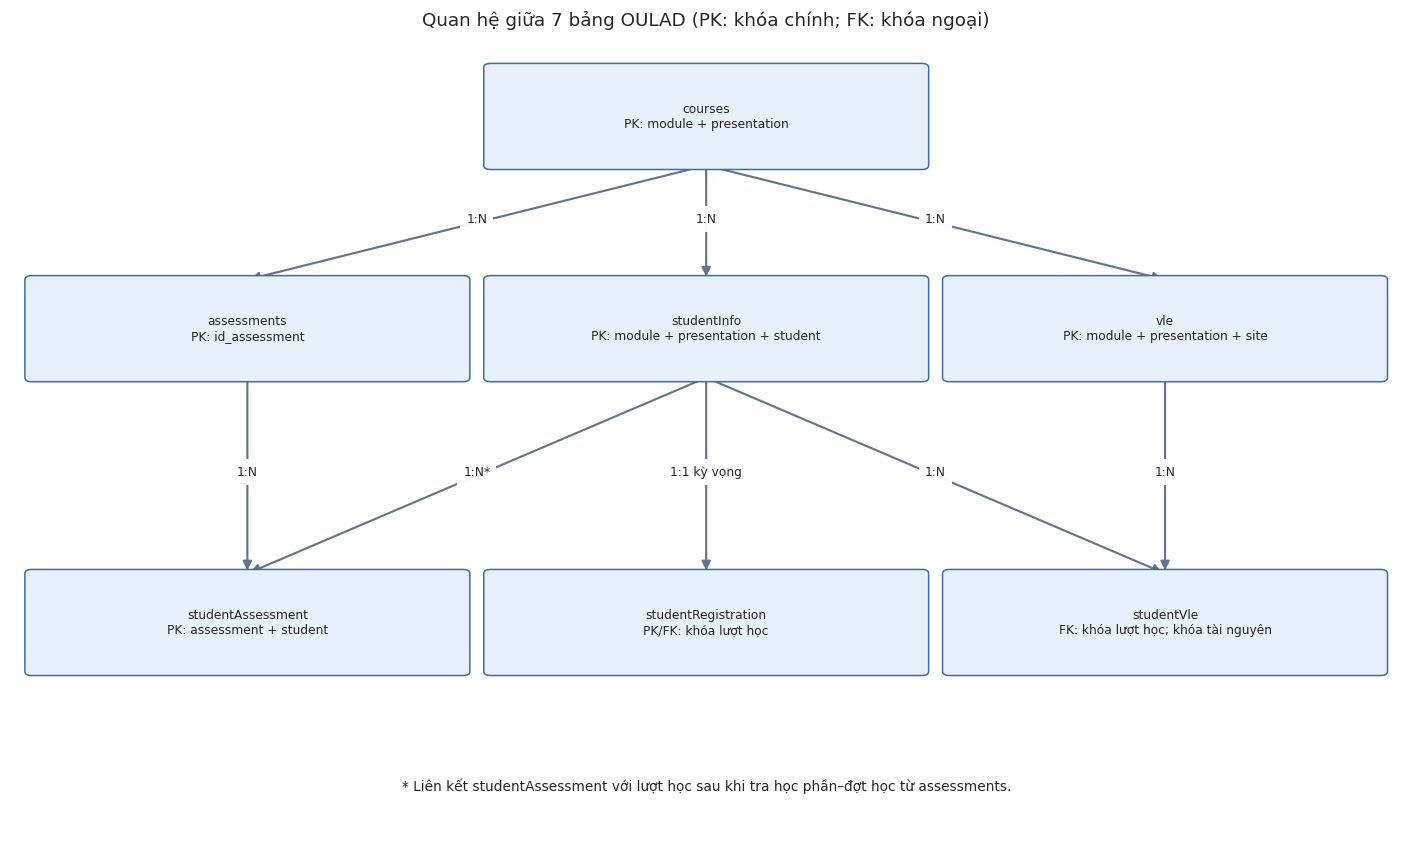

**Nhận xét:** Mũi tên đi từ bảng cha sang bảng con. Liên kết bài nộp với lượt học phải tra học phần và đợt học từ assessments; không đối chiếu id_student đơn lẻ.

In [4]:
expected_keys = {'courses': COURSE_KEY, 'assessments': ['id_assessment'],
                 'studentInfo': STUDENT_KEY, 'studentRegistration': STUDENT_KEY,
                 'studentAssessment': ['id_assessment', 'id_student'], 'vle': SITE_KEY}
key_catalog_df = pd.DataFrame([
    {'Bảng': name, 'Khóa kỳ vọng': ' + '.join(expected_keys[name]) if name in expected_keys else 'Không mặc định khóa chính cho log',
     'Liên kết chính': {
         'courses': 'Bảng cha của học phần–đợt học',
         'assessments': 'courses qua code_module + code_presentation',
         'studentInfo': 'courses qua code_module + code_presentation',
         'studentRegistration': 'studentInfo qua khóa lượt học',
         'studentAssessment': 'assessments qua id_assessment; lượt học sau khi tra đợt học',
         'vle': 'courses qua code_module + code_presentation',
         'studentVle': 'studentInfo qua khóa lượt học; vle qua khóa tài nguyên'}[name]}
    for name in NAMES])
show_table('2_1_3_key_catalog', 'Khóa kỳ vọng và đường liên kết', key_catalog_df)
comment(f'{len(expected_keys)} bảng có khóa kỳ vọng; bảng thứ bảy studentVle được kiểm tra trùng toàn dòng riêng. Cùng id_site hoặc id_student ở các đợt học cần đối chiếu đủ khóa ghép.')

fig, ax = plt.subplots(figsize=(13, 8))
positions = {'courses': (.50, .90), 'studentInfo': (.50, .64), 'assessments': (.17, .64),
             'vle': (.83, .64), 'studentRegistration': (.50, .28),
             'studentAssessment': (.17, .28), 'studentVle': (.83, .28)}
labels = {'courses': 'courses\nPK: module + presentation',
          'studentInfo': 'studentInfo\nPK: module + presentation + student',
          'assessments': 'assessments\nPK: id_assessment',
          'vle': 'vle\nPK: module + presentation + site',
          'studentRegistration': 'studentRegistration\nPK/FK: khóa lượt học',
          'studentAssessment': 'studentAssessment\nPK: assessment + student',
          'studentVle': 'studentVle\nFK: khóa lượt học; khóa tài nguyên'}
edges = [('courses', 'studentInfo', '1:N'), ('courses', 'assessments', '1:N'),
         ('courses', 'vle', '1:N'), ('studentInfo', 'studentRegistration', '1:1 kỳ vọng'),
         ('assessments', 'studentAssessment', '1:N'), ('vle', 'studentVle', '1:N'),
         ('studentInfo', 'studentVle', '1:N'), ('studentInfo', 'studentAssessment', '1:N*')]
for parent, child, label in edges:
    x0, y0 = positions[parent]; x1, y1 = positions[child]
    start, end = (x0, y0 - .06), (x1, y1 + .06)
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>', mutation_scale=12,
                                connectionstyle='arc3,rad=0', color='#64748b', lw=1.4, zorder=1))
    ax.text((x0+x1)/2, (y0+y1)/2, label, ha='center', fontsize=8,
            bbox=dict(facecolor='white', edgecolor='none', alpha=.95), zorder=2)
for name, (x, y) in positions.items():
    ax.add_patch(FancyBboxPatch((x-.155, y-.06), .31, .12, boxstyle='round,pad=0.005',
                               facecolor='#e8f0fb', edgecolor='#3b6ea8', zorder=3))
    ax.text(x, y, labels[name], ha='center', va='center', fontsize=8, zorder=4)
ax.set(xlim=(0, 1), ylim=(0, 1), title='Quan hệ giữa 7 bảng OULAD (PK: khóa chính; FK: khóa ngoại)')
ax.text(.5, .08, '* Liên kết studentAssessment với lượt học sau khi tra học phần–đợt học từ assessments.',
        ha='center', va='center', fontsize=9)
ax.axis('off')
save_figure(fig, '2_1_3_relationships', 'Sơ đồ quan hệ giữa 7 bảng')
comment('Mũi tên đi từ bảng cha sang bảng con. Liên kết bài nộp với lượt học phải tra học phần và đợt học từ assessments; không đối chiếu id_student đơn lẻ.')

## 2.2. Khám phá đặc điểm dữ liệu
### 2.2.1. Khảo sát cấu trúc, kiểu dữ liệu và miền giá trị của 7 bảng

Thống kê dưới đây bao phủ **toàn bảng** cho cả 7 bảng, kể cả VLE. Kiểu Pandas là
kiểu lúc đọc CSV, không đồng nhất với vai trò thống kê: mã số vẫn là định danh.
Miền phân loại được liệt kê đầy đủ khi có tối đa 24 giá trị; các cột định lượng/ID báo cáo khoảng quan sát.
Số giá trị khác nhau không tính giá trị thiếu. Không ép kiểu hoặc chuẩn hóa dữ liệu nguồn.

In [5]:
column_meanings = {
    'code_module': 'Mã học phần', 'code_presentation': 'Mã đợt mở lớp',
    'id_student': 'Mã sinh viên', 'id_assessment': 'Mã bài đánh giá', 'id_site': 'Mã tài nguyên',
    'module_presentation_length': 'Thời lượng đợt học (ngày)', 'assessment_type': 'Loại bài đánh giá',
    'weight': 'Trọng số (%)', 'gender': 'Giới tính', 'region': 'Vùng cư trú',
    'highest_education': 'Trình độ học vấn cao nhất', 'imd_band': 'Nhóm chỉ số thiếu thốn kinh tế xã hội',
    'age_band': 'Nhóm tuổi', 'num_of_prev_attempts': 'Số lần học trước',
    'studied_credits': 'Số tín chỉ đang học', 'disability': 'Khai báo khuyết tật',
    'final_result': 'Kết quả học tập cuối kỳ', 'date_registration': 'Ngày đăng ký tương đối',
    'date_unregistration': 'Ngày rút học tương đối', 'date_submitted': 'Ngày nộp bài tương đối',
    'is_banked': 'Cờ chuyển điểm từ lần học trước', 'score': 'Điểm (0–100)',
    'activity_type': 'Loại hoạt động VLE', 'week_from': 'Tuần bắt đầu dự kiến',
    'week_to': 'Tuần kết thúc dự kiến', 'sum_click': 'Số click trong bản ghi',
}
identifier_cols = {'code_module', 'code_presentation', 'id_student', 'id_assessment', 'id_site'}
category_cols = {'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability',
                 'assessment_type', 'activity_type', 'is_banked', 'final_result'}
attribute_rows, numeric_rows, numeric_cache = [], [], {}
for name in NAMES:
    for col, info in profiles[name].items():
        freq = info['freq']
        numeric = pd.api.types.is_numeric_dtype(freq.index.dtype)
        role = ('Định danh' if col in identifier_cols else 'Biến mục tiêu' if col == 'final_result'
                else 'Phân loại' if col in category_cols else 'Thời gian tương đối'
                if col.startswith('date') or col.startswith('week_') else 'Định lượng')
        domain = ('; '.join(str(v) for v in freq.index) if len(freq) <= 24 else
                  f'[{freq.index.min()}; {freq.index.max()}]' if numeric else
                  f'{len(freq):,} giá trị; xem bảng tần suất chuyên mục')
        attribute_rows.append({'Bảng': name, 'Cột': col,
            'Ý nghĩa / đơn vị': column_meanings.get(col, 'Hạn đánh giá (ngày tương đối)' if name == 'assessments' else 'Ngày tương tác tương đối'),
            'Kiểu Pandas': info['dtype'], 'Vai trò': role,
            'Số giá trị khác nhau': len(freq), 'Miền quan sát (không tính thiếu)': domain,
            'Phạm vi': f'Toàn bộ {row_counts[name]:,} dòng'})
        if numeric and col not in identifier_cols and col not in category_cols:
            numeric_cache[name, col] = numeric_summary(freq)
            numeric_rows.append({'Bảng': name, 'Cột': col, **numeric_cache[name, col]})
attribute_dictionary_df = pd.DataFrame(attribute_rows)
numeric_stats_df = pd.DataFrame(numeric_rows)
for name in NAMES:
    part = attribute_dictionary_df.loc[attribute_dictionary_df['Bảng'].eq(name)].drop(columns='Bảng')
    show_table(f'2_2_1_schema_{name}', f'Cấu trúc và miền giá trị – {name}', part)
    comment(f'{name} có {row_counts[name]:,} dòng và {len(part)} cột; '
            f'{part["Vai trò"].eq("Định danh").sum()} cột mang vai trò định danh. Các miền trên là giá trị quan sát, không tự động được coi là miền hợp lệ.')
show_table('2_2_1_numeric_summary', 'Thống kê mô tả toàn bộ các cột định lượng và thời gian', numeric_stats_df)
date_min = numeric_stats_df.loc[numeric_stats_df['Cột'].str.startswith('date'), 'Nhỏ nhất'].min()
comment(f'Mốc ngày nhỏ nhất quan sát được là {date_min:g}. Ngày âm phản ánh hoạt động hoặc đăng ký trước ngày bắt đầu; cần xét ngữ cảnh thay vì tự động gắn lỗi.')

**Cấu trúc và miền giá trị – courses**

Cột,Ý nghĩa / đơn vị,Kiểu Pandas,Vai trò,Số giá trị khác nhau,Miền quan sát (không tính thiếu),Phạm vi
code_module,Mã học phần,object,Định danh,7,AAA; BBB; CCC; DDD; EEE; FFF; GGG,Toàn bộ 22 dòng
code_presentation,Mã đợt mở lớp,object,Định danh,4,2013B; 2013J; 2014B; 2014J,Toàn bộ 22 dòng
module_presentation_length,Thời lượng đợt học (ngày),int64,Định lượng,7,234; 240; 241; 261; 262; 268; 269,Toàn bộ 22 dòng


**Nhận xét:** courses có 22 dòng và 3 cột; 2 cột mang vai trò định danh. Các miền trên là giá trị quan sát, không tự động được coi là miền hợp lệ.

**Cấu trúc và miền giá trị – assessments**

Cột,Ý nghĩa / đơn vị,Kiểu Pandas,Vai trò,Số giá trị khác nhau,Miền quan sát (không tính thiếu),Phạm vi
code_module,Mã học phần,object,Định danh,7,AAA; BBB; CCC; DDD; EEE; FFF; GGG,Toàn bộ 206 dòng
code_presentation,Mã đợt mở lớp,object,Định danh,4,2013B; 2013J; 2014B; 2014J,Toàn bộ 206 dòng
id_assessment,Mã bài đánh giá,int64,Định danh,206,[1752; 40088],Toàn bộ 206 dòng
assessment_type,Loại bài đánh giá,object,Phân loại,3,CMA; Exam; TMA,Toàn bộ 206 dòng
date,Hạn đánh giá (ngày tương đối),float64,Thời gian tương đối,74,[12.0; 261.0],Toàn bộ 206 dòng
weight,Trọng số (%),float64,Định lượng,24,0.0; 1.0; 2.0; 3.0; 4.0; 5.0; 6.0; 7.0; 7.5; 8.0; 9.0; 10.0; 12.5; 15.0; 16.0; 17.5; 18.0; 20.0; 22.0; 25.0; 28.0; 30.0; 35.0; 100.0,Toàn bộ 206 dòng


...

Cột,Ý nghĩa / đơn vị,Kiểu Pandas,Vai trò,Số giá trị khác nhau,Miền quan sát (không tính thiếu),Phạm vi
code_module,Mã học phần,object,Định danh,7,AAA; BBB; CCC; DDD; EEE; FFF; GGG,"Toàn bộ 10,655,280 dòng"
code_presentation,Mã đợt mở lớp,object,Định danh,4,2013B; 2013J; 2014B; 2014J,"Toàn bộ 10,655,280 dòng"
id_student,Mã sinh viên,int64,Định danh,"26,074",[6516; 2698588],"Toàn bộ 10,655,280 dòng"
id_site,Mã tài nguyên,int64,Định danh,"6,268",[526721; 1049562],"Toàn bộ 10,655,280 dòng"
date,Ngày tương tác tương đối,int64,Thời gian tương đối,295,[-25; 269],"Toàn bộ 10,655,280 dòng"
sum_click,Số click trong bản ghi,int64,Định lượng,498,[1; 6977],"Toàn bộ 10,655,280 dòng"


**Nhận xét:** studentVle có 10,655,280 dòng và 6 cột; 4 cột mang vai trò định danh. Các miền trên là giá trị quan sát, không tự động được coi là miền hợp lệ.

**Thống kê mô tả toàn bộ các cột định lượng và thời gian**

Bảng,Cột,Số quan sát có giá trị,Nhỏ nhất,Q1,Trung vị,Trung bình,Q3,P95,P99,Lớn nhất,Độ lệch chuẩn
courses,module_presentation_length,22,234.00,241.00,261.50,255.55,268.00,269.00,269.00,269.00,13.65
assessments,date,195,12.00,71.00,152.00,145.01,222.00,240.30,241.00,261.00,76.00
assessments,weight,206,0.00,0.00,12.50,20.87,24.25,100.00,100.00,100.00,30.38
studentInfo,num_of_prev_attempts,"32,593",0.00,0.00,0.00,0.16,0.00,1.00,2.00,6.00,0.48
studentInfo,studied_credits,"32,593",30.00,60.00,60.00,79.76,120.00,150.00,240.00,655.00,41.07
studentRegistration,date_registration,"32,548",-322.00,-100.00,-57.00,-69.41,-29.00,-15.00,-2.00,167.00,49.26
studentRegistration,date_unregistration,"10,072",-365.00,-2.00,27.00,49.76,109.00,202.00,228.29,444.00,82.46
studentAssessment,date_submitted,"173,912",-11.00,51.00,116.00,116.03,173.00,230.00,243.00,608.00,71.48
studentAssessment,score,"173,739",0.00,65.00,80.00,75.80,90.00,100.00,100.00,100.00,18.80
vle,week_from,"1,121",0.00,8.00,15.00,15.20,22.00,28.00,29.00,29.00,8.79


**Nhận xét:** Mốc ngày nhỏ nhất quan sát được là -365. Ngày âm phản ánh hoạt động hoặc đăng ký trước ngày bắt đầu; cần xét ngữ cảnh thay vì tự động gắn lỗi.

### 2.2.2. Phân tích phân phối biến mục tiêu `final_result`

Giữ nguyên các lớp gốc. Tỷ lệ tính trên tổng số lượt học của `studentInfo`,
không phải số sinh viên duy nhất; chưa gộp nhãn nhị phân.

**Phân phối final_result theo lượt học**

Kết quả học tập,Số lượt học,Tỷ lệ (%)
Pass,"12,361",37.93
Withdrawn,"10,156",31.16
Fail,"7,052",21.64
Distinction,"3,024",9.28


**Nhận xét:** Lớp nhiều nhất là Pass: 12,361 lượt (37.93%). Lớp ít nhất là Distinction: 3,024 lượt; tỷ số lớn nhất/nhỏ nhất là 4.09.

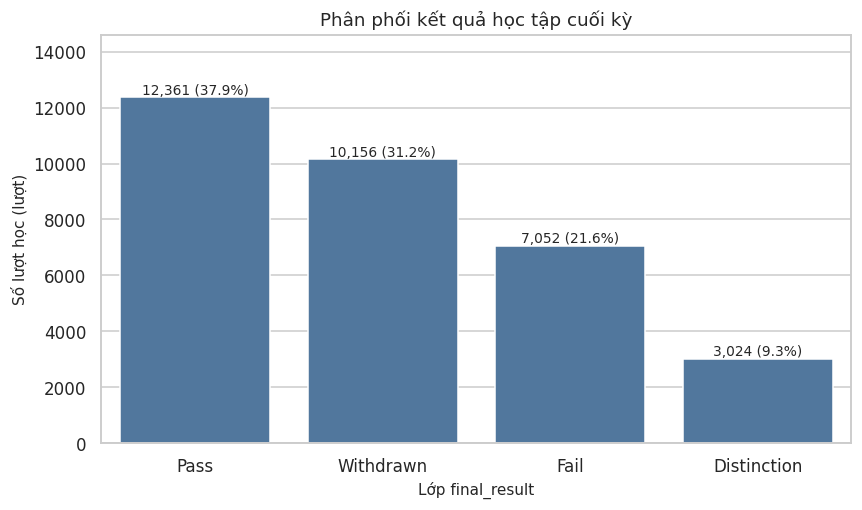

**Nhận xét:** Chênh lệch tần suất lớp trong hình cần được cân nhắc khi chọn chỉ số đánh giá ở giai đoạn mô hình; hình hiện tại chỉ mô tả phân phối nhãn gốc.

In [6]:
target_df = count_distribution(tables['studentInfo']['final_result'], 'Kết quả học tập')
show_table('2_2_2_final_result', 'Phân phối final_result theo lượt học', target_df)
largest, smallest = target_df.iloc[0], target_df.iloc[-1]
comment(f'Lớp nhiều nhất là {largest["Kết quả học tập"]}: {int(largest["Số lượt học"]):,} lượt ({largest["Tỷ lệ (%)"]:.2f}%). '
        f'Lớp ít nhất là {smallest["Kết quả học tập"]}: {int(smallest["Số lượt học"]):,} lượt; tỷ số lớn nhất/nhỏ nhất là {largest["Số lượt học"]/smallest["Số lượt học"]:.2f}.')
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.barplot(data=target_df, x='Kết quả học tập', y='Số lượt học', color='#4477aa', ax=ax)
for i, row in target_df.iterrows():
    ax.text(i, row['Số lượt học'], f'{int(row["Số lượt học"]):,} ({row["Tỷ lệ (%)"]:.1f}%)', ha='center', va='bottom', fontsize=9)
ax.set(title='Phân phối kết quả học tập cuối kỳ', xlabel='Lớp final_result', ylabel='Số lượt học (lượt)')
ax.set_ylim(0, target_df['Số lượt học'].max()*1.18)
save_figure(fig, '2_2_2_final_result', 'Phân phối final_result')
comment('Chênh lệch tần suất lớp trong hình cần được cân nhắc khi chọn chỉ số đánh giá ở giai đoạn mô hình; hình hiện tại chỉ mô tả phân phối nhãn gốc.')

### 2.2.3. Phân tích phân phối các đặc trưng nhân khẩu học

Bảng gồm `gender`, `age_band`, `highest_education`, `region`, `imd_band`, `disability`.
Mẫu số là toàn bộ lượt học; nhóm thiếu nếu có được hiển thị riêng, không điền vào cột gốc.
Chọn bốn biểu đồ giới tính, tuổi, học vấn và IMD để thể hiện cả mức độ tập trung và thiếu thông tin.

**Phân phối sáu đặc trưng nhân khẩu học (theo lượt học)**

Đặc trưng,Nhóm quan sát,Số lượt học,Tỷ lệ (%)
gender,M,"17,875",54.84
gender,F,"14,718",45.16
age_band,0-35,"22,944",70.40
age_band,35-55,"9,433",28.94
age_band,55<=,216,0.66
highest_education,A Level or Equivalent,"14,045",43.09
highest_education,Lower Than A Level,"13,158",40.37
highest_education,HE Qualification,"4,730",14.51
highest_education,No Formal quals,347,1.06
highest_education,Post Graduate Qualification,313,0.96


**Nhận xét:** Nhóm phổ biến nhất theo từng đặc trưng: gender: M (54.84%); age_band: 0-35 (70.40%); highest_education: A Level or Equivalent (43.09%); region: Scotland (10.57%); imd_band: 20-30% (11.21%); disability: N (90.29%). Một sinh viên học nhiều đợt có thể đóng góp nhiều lượt.

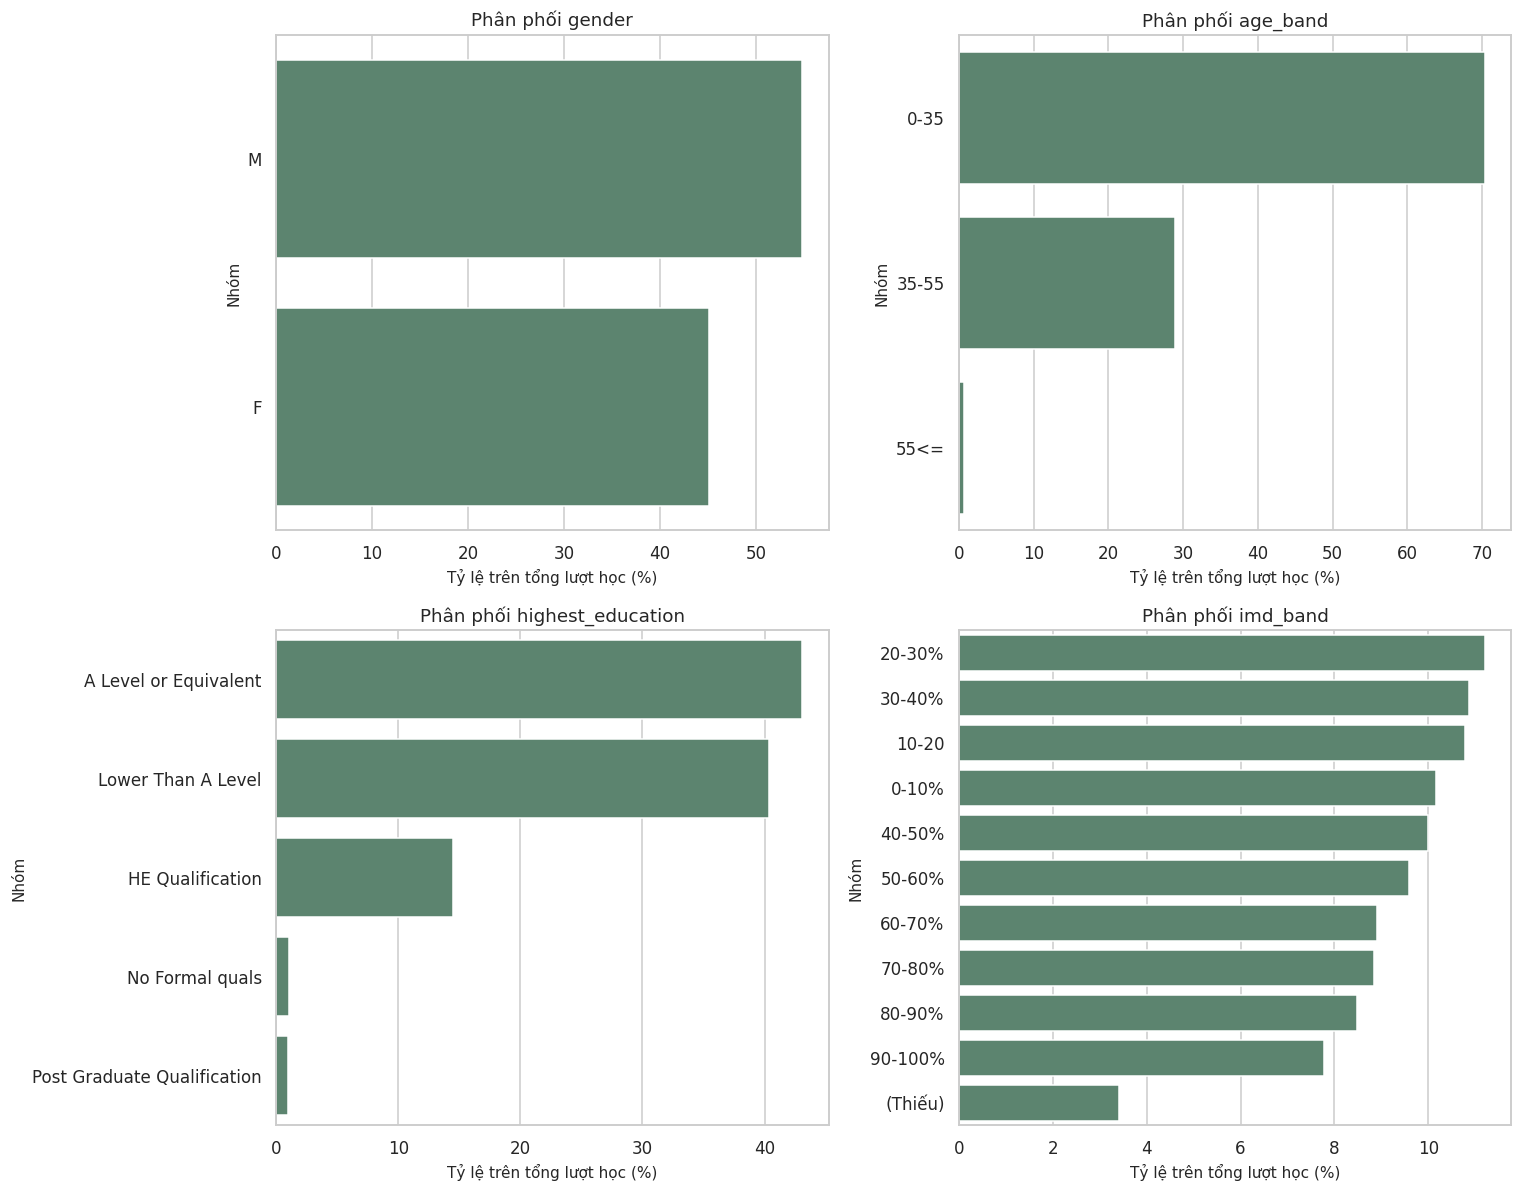

**Nhận xét:** imd_band thiếu 1,111 lượt (3.41%). Tên nhóm IMD được giữ đúng cách ghi trong CSV; hình không chuẩn hóa nhãn nhóm.

In [7]:
demographic_columns = ['gender', 'age_band', 'highest_education', 'region', 'imd_band', 'disability']
demographic_parts = []
for col in demographic_columns:
    part = count_distribution(tables['studentInfo'][col], 'Nhóm quan sát')
    part.insert(0, 'Đặc trưng', col)
    demographic_parts.append(part)
demographic_df = pd.concat(demographic_parts, ignore_index=True)
show_table('2_2_3_demographics', 'Phân phối sáu đặc trưng nhân khẩu học (theo lượt học)', demographic_df)
majorities = [f'{col}: {part.iloc[0]["Nhóm quan sát"]} ({part.iloc[0]["Tỷ lệ (%)"]:.2f}%)'
              for col, part in zip(demographic_columns, demographic_parts)]
comment('Nhóm phổ biến nhất theo từng đặc trưng: ' + '; '.join(majorities) + '. Một sinh viên học nhiều đợt có thể đóng góp nhiều lượt.')
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for ax, col in zip(axes.flat, ['gender', 'age_band', 'highest_education', 'imd_band']):
    part = demographic_df.loc[demographic_df['Đặc trưng'].eq(col)].copy()
    # Chỉ tạo nhãn hiển thị; không thay thế NA trong dữ liệu nguồn.
    part['Nhãn biểu đồ'] = part['Nhóm quan sát'].map(lambda x: '(Thiếu)' if pd.isna(x) else str(x))
    sns.barplot(data=part, x='Tỷ lệ (%)', y='Nhãn biểu đồ', color='#558b6e', ax=ax)
    ax.set(title=f'Phân phối {col}', xlabel='Tỷ lệ trên tổng lượt học (%)', ylabel='Nhóm')
save_figure(fig, '2_2_3_demographics', 'Bốn phân phối nhân khẩu học')
imd_missing = profiles['studentInfo']['imd_band']['missing']
comment(f'imd_band thiếu {imd_missing:,} lượt ({100*imd_missing/row_counts["studentInfo"]:.2f}%). '
        'Tên nhóm IMD được giữ đúng cách ghi trong CSV; hình không chuẩn hóa nhãn nhóm.')

### 2.2.4. Phân tích phân phối điểm đánh giá học tập

Đơn vị là **bài nộp**, không phải sinh viên. Bảng theo loại đánh giá được tra cứu
many-to-one từ `assessments` qua `id_assessment`, có kiểm tra khóa và số dòng.
Điểm thiếu không tham gia trung bình/phân vị nhưng vẫn được đếm trong bảng.

**Thống kê điểm trên toàn bộ bài nộp**

Biến,Số quan sát có giá trị,Nhỏ nhất,Q1,Trung vị,Trung bình,Q3,P95,P99,Lớn nhất,Độ lệch chuẩn,Số điểm thiếu
score (điểm),"173,739",0.00,65.00,80.00,75.80,90.00,100.00,100.00,100.00,18.80,173


**Nhận xét:** Có 173,739 bài nộp có điểm; trung vị 80.00, trung bình 75.80 điểm. Có 173 điểm thiếu; không suy diễn là điểm 0.

**Điểm và số bài nộp theo assessment_type**

assessment_type,Số bài nộp,Số bài có điểm,Điểm trung bình,Điểm trung vị,Độ lệch chuẩn (điểm),Số điểm thiếu,Tỷ lệ bài nộp (%)
CMA,"70,527","70,527",81.03,82.00,17.84,0,40.55
Exam,"4,959","4,959",65.57,67.00,20.58,0,2.85
TMA,"98,426","98,253",72.56,76.00,18.43,173,56.60


**Nhận xét:** Có 3 nhóm loại bài trong dữ liệu bài nộp. 0 bài nộp không khớp danh mục; khác biệt điểm giữa các loại chỉ là mô tả, chưa điều chỉnh theo học phần hay sinh viên.

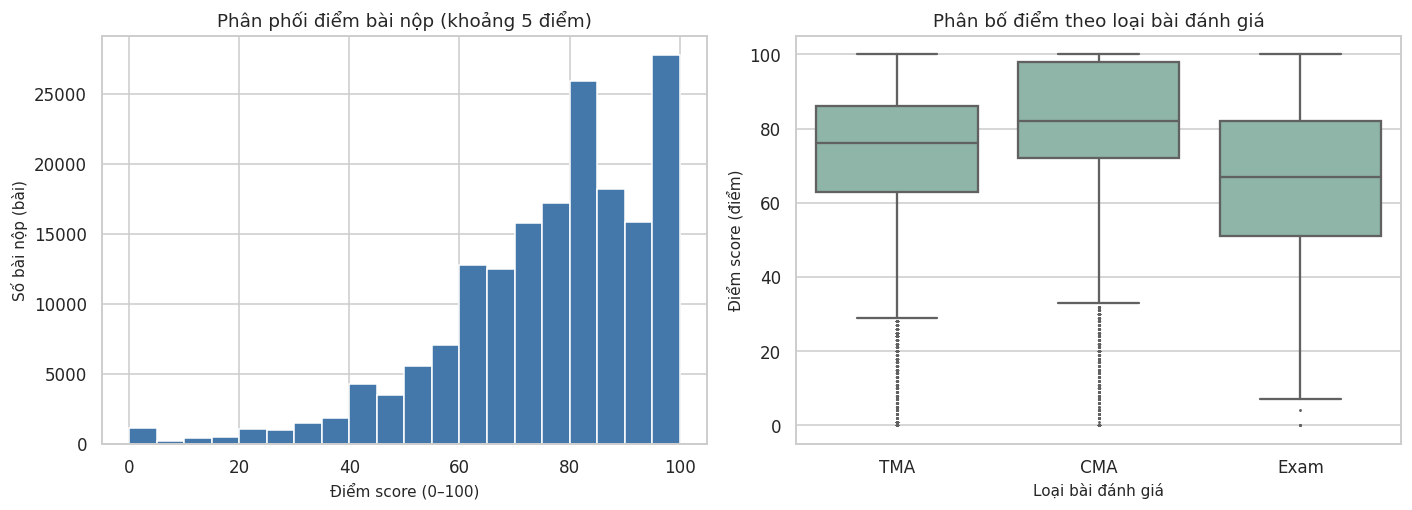

**Nhận xét:** Histogram biểu diễn 173,739 điểm trong [0,100]; 0 điểm ngoài miền này không nằm trong histogram và được kiểm tra ở 2.3.3. Dấu ngoài râu boxplot là ứng viên ngoại lai thống kê, chưa phải lỗi dữ liệu.

In [8]:
score_freq = profiles['studentAssessment']['score']['freq']
score_stats = numeric_cache['studentAssessment', 'score']
score_summary_df = pd.DataFrame([{'Biến': 'score (điểm)', **score_stats,
                                 'Số điểm thiếu': profiles['studentAssessment']['score']['missing']}])
show_table('2_2_4_score_summary', 'Thống kê điểm trên toàn bộ bài nộp', score_summary_df)
comment(f'Có {int(score_stats["Số quan sát có giá trị"]):,} bài nộp có điểm; trung vị {score_stats["Trung vị"]:.2f}, '
        f'trung bình {score_stats["Trung bình"]:.2f} điểm. Có {profiles["studentAssessment"]["score"]["missing"]:,} điểm thiếu; không suy diễn là điểm 0.')
if tables['assessments'].duplicated(['id_assessment']).any():
    raise ValueError('id_assessment không duy nhất trong assessments.')
assessment_audit = tables['studentAssessment'].merge(
    tables['assessments'][['id_assessment', 'assessment_type'] + COURSE_KEY + ['date']],
    on='id_assessment', how='left', validate='many_to_one', indicator=True)
assert len(assessment_audit) == row_counts['studentAssessment']
score_by_type_df = assessment_audit.groupby('assessment_type', dropna=False).agg(
    **{'Số bài nộp': ('id_student', 'size'), 'Số bài có điểm': ('score', 'count'),
       'Điểm trung bình': ('score', 'mean'), 'Điểm trung vị': ('score', 'median'),
       'Độ lệch chuẩn (điểm)': ('score', 'std')}).reset_index()
score_by_type_df['Số điểm thiếu'] = score_by_type_df['Số bài nộp'] - score_by_type_df['Số bài có điểm']
score_by_type_df['Tỷ lệ bài nộp (%)'] = score_by_type_df['Số bài nộp'] / len(assessment_audit) * 100
show_table('2_2_4_score_by_type', 'Điểm và số bài nộp theo assessment_type', score_by_type_df)
comment(f'Có {len(score_by_type_df)} nhóm loại bài trong dữ liệu bài nộp. '
        f'{int(assessment_audit["_merge"].eq("left_only").sum()):,} bài nộp không khớp danh mục; '
        'khác biệt điểm giữa các loại chỉ là mô tả, chưa điều chỉnh theo học phần hay sinh viên.')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
score_bins = np.arange(0, 105, 5)
hist_counts, edges = np.histogram(score_freq.index.to_numpy(dtype=float), bins=score_bins, weights=score_freq.to_numpy())
axes[0].bar(edges[:-1], hist_counts, width=np.diff(edges), align='edge', color='#4477aa', edgecolor='white')
axes[0].set(title='Phân phối điểm bài nộp (khoảng 5 điểm)', xlabel='Điểm score (0–100)', ylabel='Số bài nộp (bài)')
sns.boxplot(data=assessment_audit, x='assessment_type', y='score', color='#88bbaa', fliersize=1, ax=axes[1])
axes[1].set(title='Phân bố điểm theo loại bài đánh giá', xlabel='Loại bài đánh giá', ylabel='Điểm score (điểm)')
save_figure(fig, '2_2_4_score_distribution', 'Histogram điểm và boxplot theo loại đánh giá')
comment(f'Histogram biểu diễn {int(hist_counts.sum()):,} điểm trong [0,100]; '
        f'{int(score_freq.sum()-hist_counts.sum()):,} điểm ngoài miền này không nằm trong histogram và được kiểm tra ở 2.3.3. '
        'Dấu ngoài râu boxplot là ứng viên ngoại lai thống kê, chưa phải lỗi dữ liệu.')

### 2.2.5. Phân tích phân phối dữ liệu tương tác VLE (`sum_click`, `activity_type`)

`sum_click` được thống kê trên **toàn bộ bản ghi VLE**, không lấy 100.000 dòng đầu.
Histogram dùng các khoảng click tăng theo bậc và trục log để quan sát đuôi dài,
không biến đổi cột nguồn. Với `activity_type`, phân biệt tỷ lệ **tài nguyên**,
**bản ghi log** và **click**; không thay thế ba mẫu số này cho nhau.

**Phân phối số click trên toàn bộ nhật ký VLE**

Biến,Số quan sát có giá trị,Nhỏ nhất,Q1,Trung vị,Trung bình,Q3,P95,P99,Lớn nhất,Độ lệch chuẩn,Số giá trị thiếu
sum_click (click/bản ghi),"10,655,280",1.00,1.00,2.00,3.72,3.00,12.00,34.00,"6,977.00",8.85,0


**Nhận xét:** Có 10,655,280 bản ghi với tổng 39,605,099 click. Trung vị 2.00, trung bình 3.72, P99 34.00 và cực đại 6977 click/bản ghi.

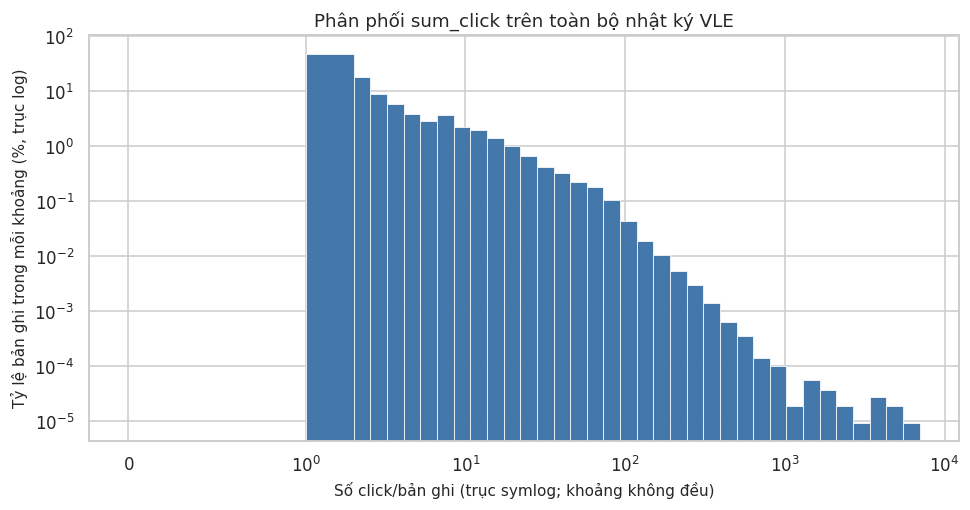

**Nhận xét:** 99.03% bản ghi có số click không vượt P99. Chiều cao cột là tỷ lệ bản ghi trong khoảng, không phải mật độ; khoảng trên trục x không đều.

**Phân phối tài nguyên, bản ghi và click theo activity_type**

Loại hoạt động,Số tài nguyên,Số bản ghi VLE,Tổng số click,Tỷ lệ tài nguyên (%),Tỷ lệ bản ghi VLE (%),Tỷ lệ click (%)
oucontent,996,"1,963,782","11,206,803",15.65,18.43,28.30
forumng,194,"2,408,457","7,973,390",3.05,22.60,20.13
quiz,127,"914,573","6,981,240",2.00,8.58,17.63
homepage,22,"1,735,226","6,949,064",0.35,16.29,17.55
subpage,"1,055","1,949,898","3,411,582",16.58,18.30,8.61
resource,"2,660","813,185","1,110,132",41.80,7.63,2.80
ouwiki,49,"178,165","894,512",0.77,1.67,2.26
url,886,"407,716","566,702",13.92,3.83,1.43
oucollaborate,82,"65,793","108,974",1.29,0.62,0.28
glossary,21,"17,435","87,962",0.33,0.16,0.22


**Nhận xét:** oucontent có nhiều click nhất: 11,206,803 (28.30%), trong khi chiếm 15.65% tài nguyên. Có 0 log không xác định được loại hoạt động.

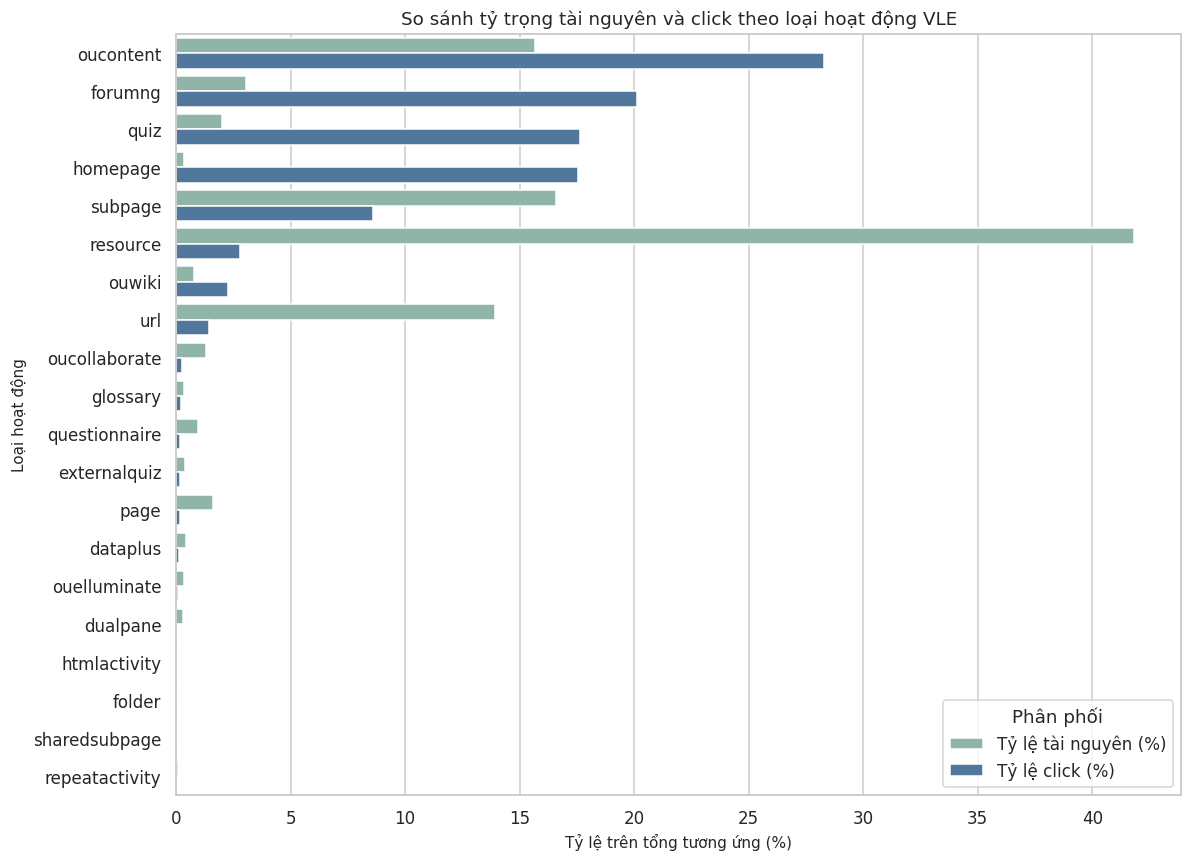

**Nhận xét:** Hai tỷ trọng dùng mẫu số riêng: tổng tài nguyên trong vle và tổng click trong studentVle. Ba loại nhiều click nhất chiếm 66.06% tổng click; không suy ra hiệu quả học tập chỉ từ mức tương tác.

In [9]:
click_freq = profiles['studentVle']['sum_click']['freq']
click_stats = numeric_cache['studentVle', 'sum_click']
click_summary_df = pd.DataFrame([{'Biến': 'sum_click (click/bản ghi)', **click_stats,
                                 'Số giá trị thiếu': profiles['studentVle']['sum_click']['missing']}])
show_table('2_2_5_click_summary', 'Phân phối số click trên toàn bộ nhật ký VLE', click_summary_df)
total_clicks = sum(int(value)*int(count) for value, count in click_freq.items())
comment(f'Có {vle_rows:,} bản ghi với tổng {total_clicks:,} click. Trung vị {click_stats["Trung vị"]:.2f}, '
        f'trung bình {click_stats["Trung bình"]:.2f}, P99 {click_stats["P99"]:.2f} và cực đại {click_stats["Lớn nhất"]:g} click/bản ghi.')

fig, ax = plt.subplots(figsize=(9, 4.8))
max_click = max(1, int(click_freq.index.max()))
click_edges = np.unique(np.r_[0, 1, np.geomspace(2, max(3, max_click+1), 35)])
click_hist, click_edges = np.histogram(click_freq.index.to_numpy(dtype=float), bins=click_edges, weights=click_freq.to_numpy())
ax.bar(click_edges[:-1], click_hist / vle_rows * 100, width=np.diff(click_edges), align='edge',
       color='#4477aa', edgecolor='white', linewidth=.5)
ax.set_xscale('symlog', linthresh=1)
ax.set_yscale('log')
ax.set(title='Phân phối sum_click trên toàn bộ nhật ký VLE',
       xlabel='Số click/bản ghi (trục symlog; khoảng không đều)',
       ylabel='Tỷ lệ bản ghi trong mỗi khoảng (%, trục log)')
save_figure(fig, '2_2_5_click_distribution', 'Phân phối sum_click toàn bộ log')
comment(f'{100*int(click_freq.loc[click_freq.index <= click_stats["P99"]].sum())/vle_rows:.2f}% bản ghi có số click không vượt P99. '
        'Chiều cao cột là tỷ lệ bản ghi trong khoảng, không phải mật độ; khoảng trên trục x không đều.')

resources = tables['vle']['activity_type'].value_counts(dropna=False)
all_kinds = sorted(set(resources.index.dropna()) | set(activity_records))
activity_df = pd.DataFrame([
    {'Loại hoạt động': kind, 'Số tài nguyên': int(resources.get(kind, 0)),
     'Số bản ghi VLE': int(activity_records.get(kind, 0)), 'Tổng số click': int(activity_clicks.get(kind, 0))}
    for kind in all_kinds])
if missing_activity_rows or tables['vle']['activity_type'].isna().any():
    activity_df.loc[len(activity_df)] = ['(Không xác định loại)', int(tables['vle']['activity_type'].isna().sum()),
                                       missing_activity_rows, total_clicks-sum(activity_clicks.values())]
activity_df['Tỷ lệ tài nguyên (%)'] = activity_df['Số tài nguyên'] / row_counts['vle'] * 100
activity_df['Tỷ lệ bản ghi VLE (%)'] = activity_df['Số bản ghi VLE'] / vle_rows * 100
activity_df['Tỷ lệ click (%)'] = activity_df['Tổng số click'] / total_clicks * 100 if total_clicks else np.nan
activity_df = activity_df.sort_values('Tổng số click', ascending=False).reset_index(drop=True)
assert int(activity_df['Số bản ghi VLE'].sum()) == vle_rows
assert int(activity_df['Tổng số click'].sum()) == total_clicks
show_table('2_2_5_activity_type', 'Phân phối tài nguyên, bản ghi và click theo activity_type', activity_df)
top_activity = activity_df.iloc[0]
comment(f'{top_activity["Loại hoạt động"]} có nhiều click nhất: {int(top_activity["Tổng số click"]):,} '
        f'({top_activity["Tỷ lệ click (%)"]:.2f}%), trong khi chiếm {top_activity["Tỷ lệ tài nguyên (%)"]:.2f}% tài nguyên. '
        f'Có {missing_activity_rows:,} log không xác định được loại hoạt động.')
fig, ax = plt.subplots(figsize=(11, 8))
plot_activity = activity_df[['Loại hoạt động', 'Tỷ lệ tài nguyên (%)', 'Tỷ lệ click (%)']].melt(
    id_vars='Loại hoạt động', var_name='Mẫu số thống kê', value_name='Tỷ lệ (%)')
sns.barplot(data=plot_activity, y='Loại hoạt động', x='Tỷ lệ (%)', hue='Mẫu số thống kê',
            order=activity_df['Loại hoạt động'], palette=['#88bbaa', '#4477aa'], ax=ax)
ax.set(title='So sánh tỷ trọng tài nguyên và click theo loại hoạt động VLE',
       xlabel='Tỷ lệ trên tổng tương ứng (%)', ylabel='Loại hoạt động')
ax.legend(title='Phân phối', loc='lower right')
save_figure(fig, '2_2_5_activity_type', 'Tỷ trọng tài nguyên và click theo activity_type')
comment('Hai tỷ trọng dùng mẫu số riêng: tổng tài nguyên trong vle và tổng click trong studentVle. '
        f'Ba loại nhiều click nhất chiếm {activity_df.head(3)["Tỷ lệ click (%)"].sum():.2f}% tổng click; không suy ra hiệu quả học tập chỉ từ mức tương tác.')

## 2.3. Đánh giá chất lượng dữ liệu
### 2.3.1. Kiểm tra giá trị thiếu trong 7 bảng

Sử dụng bộ đếm từ lần khảo sát trước, không quét lại nhật ký.
Bảng tổng quát bao phủ mọi cột, kể cả cột không thiếu; biểu đồ chỉ hiển thị cột thực sự thiếu.
Mẫu số tỷ lệ thiếu là số dòng của chính bảng đó. Không mặc định mọi giá trị thiếu là lỗi.

**Kiểm tra thiếu trên mọi cột của 7 bảng**

Bảng,Cột,Số dòng của bảng,Số giá trị thiếu,Tỷ lệ thiếu (%)
courses,code_module,22,0,0.00
courses,code_presentation,22,0,0.00
courses,module_presentation_length,22,0,0.00
assessments,code_module,206,0,0.00
assessments,code_presentation,206,0,0.00
assessments,id_assessment,206,0,0.00
assessments,assessment_type,206,0,0.00
assessments,date,206,11,5.34
assessments,weight,206,0,0.00
studentInfo,code_module,"32,593",0,0.00


**Thiếu dữ liệu theo bảng (đơn vị ô)**

Bảng,Số cột,Số ô thiếu,Tổng số ô,Tỷ lệ ô thiếu (%)
courses,3,0,66,0.00
assessments,6,11,"1,236",0.89
studentInfo,12,"1,111","391,116",0.28
studentRegistration,5,"22,566","162,965",13.85
studentAssessment,5,173,"869,560",0.02
vle,6,"10,486","38,184",27.46
studentVle,6,0,"63,931,680",0.00


**Nhận xét:** 7 trong 43 cột có giá trị thiếu; tổng 34,347 ô thiếu. studentVle có 0 ô thiếu trên toàn bộ log. Tổng ô thiếu không đồng nghĩa với số dòng bị ảnh hưởng vì một dòng có thể thiếu nhiều cột.

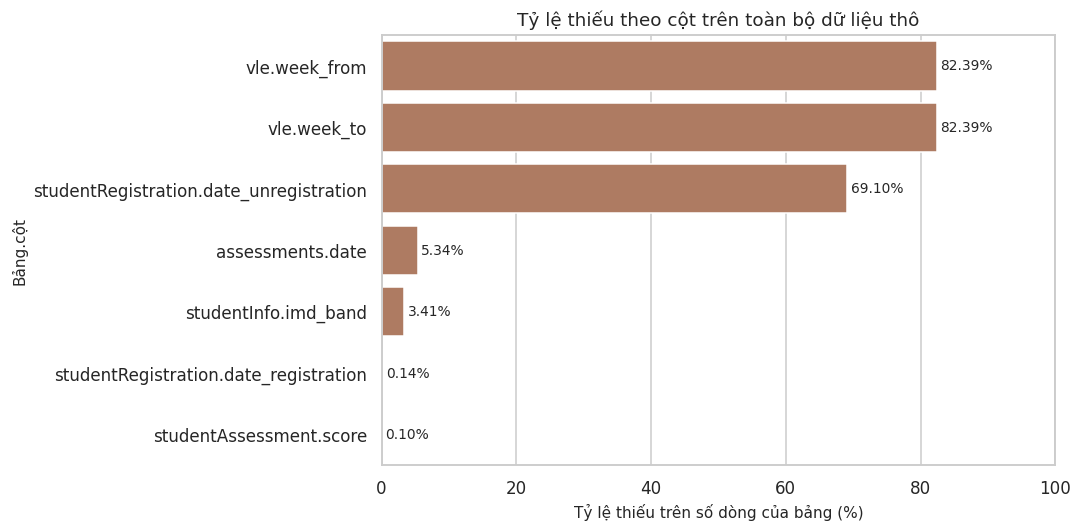

**Nhận xét:** Cột thiếu nhiều nhất theo tỷ lệ là vle.week_from: 82.39%. date_unregistration trống có thể phản ánh không ghi nhận rút học; cần đối chiếu final_result trước khi đề xuất xử lý.

**Ngữ cảnh thiếu hạn đánh giá theo loại bài**

assessment_type,Số bài đánh giá,Số ngày đến hạn có giá trị,Số ngày đến hạn thiếu,Tỷ lệ thiếu ngày (%)
CMA,76,76,0,0.00
Exam,24,13,11,45.83
TMA,106,106,0,0.00


**Nhận xét:** Bảng phân tách ngày đến hạn thiếu theo loại bài để tránh điền một giá trị chung cho mọi loại. Tổng 11 bài đánh giá thiếu ngày đến hạn; hiện chưa điền hoặc suy diễn ngày.

In [10]:
missing_df = pd.DataFrame([
    {'Bảng': name, 'Cột': col, 'Số dòng của bảng': row_counts[name],
     'Số giá trị thiếu': info['missing'], 'Tỷ lệ thiếu (%)': 100*info['missing']/row_counts[name]}
    for name in NAMES for col, info in profiles[name].items()])
show_table('2_3_1_missing_all_columns', 'Kiểm tra thiếu trên mọi cột của 7 bảng', missing_df)
missing_nonzero = missing_df.loc[missing_df['Số giá trị thiếu'].gt(0)].sort_values('Tỷ lệ thiếu (%)', ascending=False)
missing_table_df = missing_df.groupby('Bảng', sort=False).agg(
    **{'Số cột': ('Cột', 'size'), 'Số ô thiếu': ('Số giá trị thiếu', 'sum')}).reset_index()
missing_table_df['Tổng số ô'] = missing_table_df['Bảng'].map(row_counts) * missing_table_df['Số cột']
missing_table_df['Tỷ lệ ô thiếu (%)'] = missing_table_df['Số ô thiếu'] / missing_table_df['Tổng số ô'] * 100
show_table('2_3_1_missing_by_table', 'Thiếu dữ liệu theo bảng (đơn vị ô)', missing_table_df)
comment(f'{len(missing_nonzero)} trong {len(missing_df)} cột có giá trị thiếu; tổng {int(missing_df["Số giá trị thiếu"].sum()):,} ô thiếu. '
        f'studentVle có {int(missing_df.loc[missing_df["Bảng"].eq("studentVle"), "Số giá trị thiếu"].sum()):,} ô thiếu trên toàn bộ log. '
        'Tổng ô thiếu không đồng nghĩa với số dòng bị ảnh hưởng vì một dòng có thể thiếu nhiều cột.')
if len(missing_nonzero):
    fig, ax = plt.subplots(figsize=(10, 5))
    plot_missing = missing_nonzero.assign(Nhãn=missing_nonzero['Bảng'] + '.' + missing_nonzero['Cột'])
    sns.barplot(data=plot_missing, y='Nhãn', x='Tỷ lệ thiếu (%)', color='#bb7755', ax=ax)
    for i, (_, row) in enumerate(plot_missing.iterrows()):
        ax.text(row['Tỷ lệ thiếu (%)']+.5, i, f'{row["Tỷ lệ thiếu (%)"]:.2f}%', va='center', fontsize=9)
    ax.set(title='Tỷ lệ thiếu theo cột trên toàn bộ dữ liệu thô', xlabel='Tỷ lệ thiếu trên số dòng của bảng (%)', ylabel='Bảng.cột')
    ax.set_xlim(0, max(100, plot_missing['Tỷ lệ thiếu (%)'].max()+10))
    save_figure(fig, '2_3_1_missing_values', 'Tỷ lệ thiếu theo cột')
    worst = missing_nonzero.iloc[0]
    comment(f'Cột thiếu nhiều nhất theo tỷ lệ là {worst["Bảng"]}.{worst["Cột"]}: {worst["Tỷ lệ thiếu (%)"]:.2f}%. '
            'date_unregistration trống có thể phản ánh không ghi nhận rút học; cần đối chiếu final_result trước khi đề xuất xử lý.')
assessment_missing_date_df = tables['assessments'].groupby('assessment_type', dropna=False).agg(
    **{'Số bài đánh giá': ('id_assessment', 'size'), 'Số ngày đến hạn có giá trị': ('date', 'count')}).reset_index()
assessment_missing_date_df['Số ngày đến hạn thiếu'] = assessment_missing_date_df['Số bài đánh giá'] - assessment_missing_date_df['Số ngày đến hạn có giá trị']
assessment_missing_date_df['Tỷ lệ thiếu ngày (%)'] = assessment_missing_date_df['Số ngày đến hạn thiếu'] / assessment_missing_date_df['Số bài đánh giá'] * 100
show_table('2_3_1_assessment_date_context', 'Ngữ cảnh thiếu hạn đánh giá theo loại bài', assessment_missing_date_df)
comment('Bảng phân tách ngày đến hạn thiếu theo loại bài để tránh điền một giá trị chung cho mọi loại. '
        f'Tổng {int(assessment_missing_date_df["Số ngày đến hạn thiếu"].sum()):,} bài đánh giá thiếu ngày đến hạn; hiện chưa điền hoặc suy diễn ngày.')

### 2.3.2. Kiểm tra bản ghi trùng lặp

**Trùng toàn dòng:** số dòng dư sau lần xuất hiện đầu (`keep="first"`). Với VLE, kiểm tra toàn bộ
giá trị ở mọi cột trên các phân vùng, bao gồm trường hợp trùng nằm ở hai khối đọc khác nhau.
**Trùng khóa:** số dòng tham gia nhóm trùng khóa (`keep=False`), có mẫu số khác ý nghĩa với dòng dư.
Chỉ phát hiện, chưa xóa bất cứ bản ghi nào.

In [11]:
duplicate_df = pd.DataFrame([
    {'Bảng': name, 'Số dòng': row_counts[name], 'Số dòng dư trùng toàn dòng': exact_duplicates[name],
     'Tỷ lệ dòng dư (%)': 100*exact_duplicates[name]/row_counts[name], 'Phạm vi': 'Toàn bảng; xuyên khối' if name == 'studentVle' else 'Toàn bảng'}
    for name in NAMES])
show_table('2_3_2_exact_duplicates', 'Kiểm toán trùng toàn dòng trên 7 bảng', duplicate_df)
comment(f'Phát hiện {sum(exact_duplicates.values()):,} dòng dư trùng hoàn toàn; '
        f'riêng studentVle có {exact_duplicates["studentVle"]:,} dòng ({100*exact_duplicates["studentVle"]/vle_rows:.4f}%). '
        'Đây là số liệu kiểm toán, chưa đủ để xác định log trùng là lỗi thu thập hay sự kiện được ghi nhận lặp.')
key_check_df = pd.DataFrame([
    {'Bảng': name, 'Khóa kỳ vọng': ' + '.join(key), 'Số dòng': len(tables[name]),
     'Dòng thiếu thành phần khóa': int(tables[name][key].isna().any(axis=1).sum()),
     'Dòng thuộc nhóm trùng khóa': int(tables[name].duplicated(key, keep=False).sum()),
     'Tỷ lệ dòng thuộc nhóm trùng khóa (%)': 100*tables[name].duplicated(key, keep=False).sum()/len(tables[name])}
    for name, key in expected_keys.items()])
show_table('2_3_2_key_checks', 'Kiểm tra khóa kỳ vọng của 6 bảng có khóa', key_check_df)
comment(f'{int(key_check_df["Dòng thiếu thành phần khóa"].sum()):,} dòng thiếu thành phần khóa và '
        f'{int(key_check_df["Dòng thuộc nhóm trùng khóa"].sum()):,} dòng tham gia nhóm trùng khóa trên 6 bảng. '
        'Không áp đặt khóa duy nhất sinh viên–tài nguyên–ngày cho studentVle.')

**Kiểm toán trùng toàn dòng trên 7 bảng**

Bảng,Số dòng,Số dòng dư trùng toàn dòng,Tỷ lệ dòng dư (%),Phạm vi
courses,22,0,0.00,Toàn bảng
assessments,206,0,0.00,Toàn bảng
studentInfo,"32,593",0,0.00,Toàn bảng
studentRegistration,"32,593",0,0.00,Toàn bảng
studentAssessment,"173,912",0,0.00,Toàn bảng
vle,"6,364",0,0.00,Toàn bảng
studentVle,"10,655,280","787,170",7.39,Toàn bảng; xuyên khối


**Nhận xét:** Phát hiện 787,170 dòng dư trùng hoàn toàn; riêng studentVle có 787,170 dòng (7.3876%). Đây là số liệu kiểm toán, chưa đủ để xác định log trùng là lỗi thu thập hay sự kiện được ghi nhận lặp.

**Kiểm tra khóa kỳ vọng của 6 bảng có khóa**

Bảng,Khóa kỳ vọng,Số dòng,Dòng thiếu thành phần khóa,Dòng thuộc nhóm trùng khóa,Tỷ lệ dòng thuộc nhóm trùng khóa (%)
courses,code_module + code_presentation,22,0,0,0.00
assessments,id_assessment,206,0,0,0.00
studentInfo,code_module + code_presentation + id_student,"32,593",0,0,0.00
studentRegistration,code_module + code_presentation + id_student,"32,593",0,0,0.00
studentAssessment,id_assessment + id_student,"173,912",0,0,0.00
vle,code_module + code_presentation + id_site,"6,364",0,0,0.00


**Nhận xét:** 0 dòng thiếu thành phần khóa và 0 dòng tham gia nhóm trùng khóa trên 6 bảng. Không áp đặt khóa duy nhất sinh viên–tài nguyên–ngày cho studentVle.

### 2.3.3. Kiểm tra giá trị không hợp lệ và ngoại lai

Tách **vi phạm miền có quy tắc rõ ràng** khỏi **ngoại lai thống kê**.
Các kiểm tra số loại giá trị thiếu khỏi mẫu số; thiếu được báo cáo ở 2.3.1.
Ngưỡng Tukey là Q1 − 1,5×IQR và Q3 + 1,5×IQR. Phân vị VLE tính chính xác từ bảng tần suất.
Không dùng ngày âm hoặc click cao làm điều kiện tự động loại dữ liệu.

In [12]:
invalid_rows = []
def add_frequency_rule(name, col, description, invalid_predicate):
    freq = profiles[name][col]['freq']
    bad_values = invalid_predicate(freq.index)
    count = int(freq.loc[bad_values].sum())
    n = int(freq.sum())
    invalid_rows.append({'Bảng': name, 'Cột': col, 'Quy tắc hợp lệ': description,
                         'Số giá trị đã kiểm tra': n, 'Số vi phạm': count,
                         'Tỷ lệ vi phạm (%)': 100*count/n if n else np.nan})

for name in NAMES:
    for col in profiles[name]:
        if col in {'id_student', 'id_site', 'id_assessment'}:
            add_frequency_rule(name, col, 'ID nguyên dương', lambda x: (x <= 0) | (x % 1 != 0))
        elif col == 'code_module':
            add_frequency_rule(name, col, 'Mã gồm 3 chữ hoa', lambda x: ~x.astype(str).str.fullmatch(r'[A-Z]{3}'))
        elif col == 'code_presentation':
            add_frequency_rule(name, col, 'Mã năm 20xx và kỳ B/J', lambda x: ~x.astype(str).str.fullmatch(r'20[0-9]{2}[BJ]'))
        elif col.startswith('date'):
            add_frequency_rule(name, col, 'Số ngày tương đối là số nguyên (cho phép âm)', lambda x: x % 1 != 0)
        elif col in {'score', 'weight'}:
            add_frequency_rule(name, col, 'Giá trị thuộc [0,100]', lambda x: (x < 0) | (x > 100))
        elif col in {'sum_click', 'num_of_prev_attempts', 'studied_credits'}:
            add_frequency_rule(name, col, 'Số nguyên không âm', lambda x: (x < 0) | (x % 1 != 0))
        elif col == 'module_presentation_length':
            add_frequency_rule(name, col, 'Số ngày nguyên dương', lambda x: (x <= 0) | (x % 1 != 0))
        elif col in {'week_from', 'week_to'}:
            add_frequency_rule(name, col, 'Số tuần nguyên không âm', lambda x: (x < 0) | (x % 1 != 0))

allowed_categories = {
    ('studentInfo', 'final_result'): {'Pass', 'Distinction', 'Fail', 'Withdrawn'},
    ('studentInfo', 'gender'): {'M', 'F'}, ('studentInfo', 'disability'): {'Y', 'N'},
    ('studentInfo', 'age_band'): {'0-35', '35-55', '55<='},
    ('studentInfo', 'highest_education'): {'No Formal quals', 'Lower Than A Level', 'A Level or Equivalent', 'HE Qualification', 'Post Graduate Qualification'},
    ('assessments', 'assessment_type'): {'TMA', 'CMA', 'Exam'},
    ('studentAssessment', 'is_banked'): {0, 1},
}
for (name, col), allowed in allowed_categories.items():
    add_frequency_rule(name, col, 'Thuộc tập: ' + ', '.join(map(str, sorted(allowed))), lambda x, a=allowed: ~x.isin(a))
add_frequency_rule('studentInfo', 'imd_band', 'Dải thập phân vị từ 0-10 đến 90-100; hậu tố % tùy cách ghi nguồn',
                   lambda x: ~x.astype(str).str.fullmatch(r'(?:0-10|10-20|20-30|30-40|40-50|50-60|60-70|70-80|80-90|90-100)%?'))
for name in NAMES:
    for col, info in profiles[name].items():
        if not pd.api.types.is_numeric_dtype(info['freq'].index.dtype):
            add_frequency_rule(name, col, 'Không rỗng / không có khoảng trắng ở đầu hoặc cuối',
                               lambda x: (x.astype(str).str.strip() == '') | (x.astype(str) != x.astype(str).str.strip()))
invalid_df = pd.DataFrame(invalid_rows)
show_table('2_3_3_invalid_values', 'Kiểm tra miền hợp lệ (không bao gồm NA)', invalid_df)
comment(f'Đã thực hiện {len(invalid_df)} phép kiểm tra miền, ghi nhận {int(invalid_df["Số vi phạm"].sum()):,} lượt vi phạm. '
        'Một giá trị có thể vi phạm nhiều quy tắc; đây không phải số bản ghi lỗi duy nhất. Tập quy tắc này không khẳng định phát hiện mọi lỗi nghiệp vụ có thể có.')

outlier_rows = []
for name, col in [('studentAssessment', 'score'), ('studentInfo', 'studied_credits'),
                  ('studentInfo', 'num_of_prev_attempts'), ('studentVle', 'sum_click')]:
    freq = profiles[name][col]['freq']
    q1, q3 = numeric_cache[name, col]['Q1'], numeric_cache[name, col]['Q3']
    iqr = q3-q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    below, above = int(freq.loc[freq.index < lower].sum()), int(freq.loc[freq.index > upper].sum())
    outlier_rows.append({'Bảng': name, 'Cột': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                         'Ngưỡng dưới': lower, 'Ngưỡng trên': upper, 'Số dưới ngưỡng': below,
                         'Số trên ngưỡng': above, 'Số có giá trị': int(freq.sum()),
                         'Tỷ lệ ứng viên ngoại lai (%)': 100*(below+above)/freq.sum()})
outlier_df = pd.DataFrame(outlier_rows)
show_table('2_3_3_iqr_outliers', 'Ứng viên ngoại lai theo quy tắc Tukey trên dữ liệu thô', outlier_df)
click_outlier = outlier_df.loc[outlier_df['Cột'].eq('sum_click')].iloc[0]
comment(f'sum_click có {int(click_outlier["Số trên ngưỡng"]):,} bản ghi trên ngưỡng IQR {click_outlier["Ngưỡng trên"]:g} click '
        f'({click_outlier["Tỷ lệ ứng viên ngoại lai (%)"]:.2f}% ứng viên cả hai phía). '
        'Nếu IQR bằng 0, quy tắc Tukey nhạy với mọi giá trị khác tứ phân vị; các biến rời rạc và đuôi dài cần được diễn giải theo ngữ cảnh. Không cắt ngưỡng hoặc xóa dòng.')

**Kiểm tra miền hợp lệ (không bao gồm NA)**

Bảng,Cột,Quy tắc hợp lệ,Số giá trị đã kiểm tra,Số vi phạm,Tỷ lệ vi phạm (%)
courses,code_module,Mã gồm 3 chữ hoa,22,0,0.00
courses,code_presentation,Mã năm 20xx và kỳ B/J,22,0,0.00
courses,module_presentation_length,Số ngày nguyên dương,22,0,0.00
assessments,code_module,Mã gồm 3 chữ hoa,206,0,0.00
assessments,code_presentation,Mã năm 20xx và kỳ B/J,206,0,0.00
assessments,id_assessment,ID nguyên dương,206,0,0.00
assessments,date,Số ngày tương đối là số nguyên (cho phép âm),195,0,0.00
assessments,weight,"Giá trị thuộc [0,100]",206,0,0.00
studentInfo,code_module,Mã gồm 3 chữ hoa,"32,593",0,0.00
studentInfo,code_presentation,Mã năm 20xx và kỳ B/J,"32,593",0,0.00


**Nhận xét:** Đã thực hiện 62 phép kiểm tra miền, ghi nhận 0 lượt vi phạm. Một giá trị có thể vi phạm nhiều quy tắc; đây không phải số bản ghi lỗi duy nhất. Tập quy tắc này không khẳng định phát hiện mọi lỗi nghiệp vụ có thể có.

**Ứng viên ngoại lai theo quy tắc Tukey trên dữ liệu thô**

Bảng,Cột,Q1,Q3,IQR,Ngưỡng dưới,Ngưỡng trên,Số dưới ngưỡng,Số trên ngưỡng,Số có giá trị,Tỷ lệ ứng viên ngoại lai (%)
studentAssessment,score,65.00,90.00,25.00,27.50,127.50,"3,813",0,"173,739",2.19
studentInfo,studied_credits,60.00,120.00,60.00,-30.00,210.00,0,350,"32,593",1.07
studentInfo,num_of_prev_attempts,0.00,0.00,0.00,0.00,0.00,0,"4,172","32,593",12.80
studentVle,sum_click,1.00,3.00,2.00,-2.00,6.00,0,"1,314,646","10,655,280",12.34


**Nhận xét:** sum_click có 1,314,646 bản ghi trên ngưỡng IQR 6 click (12.34% ứng viên cả hai phía). Nếu IQR bằng 0, quy tắc Tukey nhạy với mọi giá trị khác tứ phân vị; các biến rời rạc và đuôi dài cần được diễn giải theo ngữ cảnh. Không cắt ngưỡng hoặc xóa dòng.

### 2.3.4. Kiểm tra tính nhất quán và toàn vẹn quan hệ

Đối chiếu đủ khóa học phần–đợt học–sinh viên/tài nguyên, kiểm tra khóa cha duy nhất,
và đếm **dòng con không khớp** với mẫu số là số dòng con. Bài nộp được tra đợt học từ
`assessments` rồi đối chiếu lượt học, không chỉ kiểm tra sinh viên có tồn tại toàn cục.
Các ngày nằm ngoài thời lượng hoặc trạng thái rút học không khớp được gắn cờ **cần rà soát ngữ cảnh**,
không tự coi là lỗi. Tên nhóm IMD khác quy ước cũng chỉ được ghi nhận.

In [13]:
relation_rows = []
def relation_check(child_label, child, parent_name, keys):
    parent = tables[parent_name]
    unique = not parent.duplicated(keys).any()
    no_missing = not parent[keys].isna().any(axis=None)
    parent_index = pd.MultiIndex.from_frame(parent[keys])
    child_index = pd.MultiIndex.from_frame(child[keys])
    missing_keys = int(child[keys].isna().any(axis=1).sum())
    # NA ở khóa con luôn được xem là không có quan hệ xác định.
    unmatched = int((~child_index.isin(parent_index) | child[keys].isna().any(axis=1).to_numpy()).sum())
    relation_rows.append({'Bảng con / phạm vi': child_label, 'Bảng cha': parent_name,
                          'Khóa liên kết': ' + '.join(keys), 'Số dòng con': len(child),
                          'Khóa cha duy nhất và không thiếu': unique and no_missing,
                          'Dòng thiếu khóa con': missing_keys, 'Dòng không khớp': unmatched,
                          'Tỷ lệ không khớp (%)': 100*unmatched/len(child) if len(child) else 0})

for child_name, parent_name, keys in [
    ('assessments', 'courses', COURSE_KEY), ('studentInfo', 'courses', COURSE_KEY),
    ('studentRegistration', 'courses', COURSE_KEY), ('vle', 'courses', COURSE_KEY),
    ('studentRegistration', 'studentInfo', STUDENT_KEY), ('studentInfo', 'studentRegistration', STUDENT_KEY),
    ('studentAssessment', 'assessments', ['id_assessment'])]:
    relation_check(child_name, tables[child_name], parent_name, keys)
relation_check('studentAssessment (đã tra đợt học từ assessments)', assessment_audit, 'studentInfo', STUDENT_KEY)
for parent_name, keys in [('courses', COURSE_KEY), ('studentInfo', STUDENT_KEY), ('vle', SITE_KEY)]:
    relation_rows.append({'Bảng con / phạm vi': 'studentVle (toàn bộ)', 'Bảng cha': parent_name,
                          'Khóa liên kết': ' + '.join(keys), 'Số dòng con': vle_rows,
                          'Khóa cha duy nhất và không thiếu': True,
                          'Dòng thiếu khóa con': 0 if not any(vle_missing[k] for k in keys) else np.nan,
                          'Dòng không khớp': vle_orphans[parent_name],
                          'Tỷ lệ không khớp (%)': 100*vle_orphans[parent_name]/vle_rows})
relation_df = pd.DataFrame(relation_rows)
show_table('2_3_4_referential_integrity', 'Kiểm tra toàn vẹn quan hệ trên toàn bộ dữ liệu', relation_df)
comment(f'{len(relation_df)} hướng đối chiếu có tổng {int(relation_df["Dòng không khớp"].sum()):,} lượt dòng không khớp. '
        f'{int(relation_df["Khóa cha duy nhất và không thiếu"].sum())}/{len(relation_df)} hướng có khóa cha đạt yêu cầu. '
        'Một dòng có thể xuất hiện ở nhiều phép đối chiếu; không cộng thành số dòng lỗi duy nhất.')

registration_audit = tables['studentRegistration'].merge(
    tables['studentInfo'][STUDENT_KEY+['final_result']], on=STUDENT_KEY, how='left', validate='one_to_one')
registration_audit = registration_audit.merge(tables['courses'], on=COURSE_KEY, how='left', validate='many_to_one')
r = registration_audit
temporal_rows = []
def add_context(label, count, n, interpretation):
    temporal_rows.append({'Kiểm tra': label, 'Số trường hợp': int(count), 'Mẫu số đã kiểm tra': int(n),
                          'Tỷ lệ (%)': 100*count/n if n else np.nan, 'Diễn giải': interpretation})
both_dates = r['date_registration'].notna() & r['date_unregistration'].notna()
add_context('Ngày đăng ký sau ngày rút học', (both_dates & r['date_registration'].gt(r['date_unregistration'])).sum(), both_dates.sum(), 'Vi phạm thứ tự thời gian; cần truy nguyên')
has_withdrawal = r['date_unregistration'].notna()
add_context('Có ngày rút học nhưng final_result khác Withdrawn', (has_withdrawal & r['final_result'].notna() & r['final_result'].ne('Withdrawn')).sum(), (has_withdrawal & r['final_result'].notna()).sum(), 'Rà soát ngữ cảnh trạng thái; chưa tự kết luận lỗi')
is_withdrawn = r['final_result'].eq('Withdrawn')
add_context('final_result Withdrawn nhưng thiếu ngày rút', (is_withdrawn & ~has_withdrawal).sum(), is_withdrawn.sum(), 'Rà soát mức đầy đủ của mốc rút học')
add_context('Ngày đăng ký âm', r['date_registration'].lt(0).sum(), r['date_registration'].notna().sum(), 'Có thể hợp lệ: đăng ký trước ngày bắt đầu')
has_length = has_withdrawal & r['module_presentation_length'].notna()
add_context('Ngày rút sau thời lượng đợt học', (has_length & r['date_unregistration'].gt(r['module_presentation_length'])).sum(), has_length.sum(), 'Rà soát ngữ cảnh hành chính, không tự xóa')
weeks = tables['vle'][['week_from', 'week_to']]
both_weeks = weeks.notna().all(axis=1)
add_context('week_from > week_to', (both_weeks & weeks['week_from'].gt(weeks['week_to'])).sum(), both_weeks.sum(), 'Vi phạm thứ tự tuần nếu có đủ hai mốc')
for label, count in vle_date_context.items():
    add_context('Log VLE: ' + label, count, vle_rows, 'Mốc ngày tương đối; chỉ mô tả, chưa loại dòng')
imd_freq = profiles['studentInfo']['imd_band']['freq']
percent_labels = [str(label) for label in imd_freq.index if str(label).endswith('%')]
no_percent_labels = [str(label) for label in imd_freq.index if not str(label).endswith('%')]
if percent_labels and len(percent_labels) < len(imd_freq):
    add_context('imd_band: nhãn không có hậu tố % (khác đa số nhóm)',
                sum(int(imd_freq[label]) for label in imd_freq.index if not str(label).endswith('%')),
                int(imd_freq.sum()), 'Khác quy ước nhãn nguồn; chưa chuẩn hóa')
consistency_df = pd.DataFrame(temporal_rows)
show_table('2_3_4_consistency_context', 'Tính nhất quán thời gian, trạng thái và cách ghi nhãn', consistency_df)
context_count = int(consistency_df.loc[consistency_df['Kiểm tra'].eq('Ngày đăng ký sau ngày rút học'), 'Số trường hợp'].iloc[0])
comment(f'Có {context_count:,} lượt đăng ký sau ngày rút học; {vle_date_context["Trước ngày bắt đầu"]:,} log trước ngày bắt đầu '
        f'và {vle_date_context["Sau thời lượng đợt học"]:,} log sau thời lượng đợt học. '
        f'Các nhãn IMD không có hậu tố % là {", ".join(no_percent_labels) or "không có"}; giữ nguyên cách ghi trong CSV.')

# Trọng số Exam và bài trong kỳ được thống kê riêng; không mặc định tổng chung phải bằng 100.
weight_audit = tables['assessments'].assign(
    **{'Nhóm đánh giá': np.where(tables['assessments']['assessment_type'].eq('Exam'), 'Exam', 'Trong kỳ (TMA/CMA)')})
weight_df = weight_audit.groupby(COURSE_KEY+['Nhóm đánh giá'], dropna=False).agg(
    **{'Số bài đánh giá': ('id_assessment', 'size'), 'Số trọng số có giá trị': ('weight', 'count'),
       'Tổng trọng số (%)': ('weight', lambda s: s.sum(min_count=1))}).reset_index()
show_table('2_3_4_weights_by_course', 'Trọng số theo đợt học và nhóm đánh giá', weight_df)
comment(f'Có {len(weight_df)} nhóm học phần–đợt học–loại đánh giá; '
        f'{int(weight_df["Tổng trọng số (%)"].eq(100).sum())} nhóm có tổng trọng số 100%. '
        'Trọng số giữa Exam và bài trong kỳ không được cộng để tự động áp quy tắc tổng bằng 100%.')

**Kiểm tra toàn vẹn quan hệ trên toàn bộ dữ liệu**

Bảng con / phạm vi,Bảng cha,Khóa liên kết,Số dòng con,Khóa cha duy nhất và không thiếu,Dòng thiếu khóa con,Dòng không khớp,Tỷ lệ không khớp (%)
assessments,courses,code_module + code_presentation,206,1.00,0,0,0.00
studentInfo,courses,code_module + code_presentation,"32,593",1.00,0,0,0.00
studentRegistration,courses,code_module + code_presentation,"32,593",1.00,0,0,0.00
vle,courses,code_module + code_presentation,"6,364",1.00,0,0,0.00
studentRegistration,studentInfo,code_module + code_presentation + id_student,"32,593",1.00,0,0,0.00
studentInfo,studentRegistration,code_module + code_presentation + id_student,"32,593",1.00,0,0,0.00
studentAssessment,assessments,id_assessment,"173,912",1.00,0,0,0.00
studentAssessment (đã tra đợt học từ assessments),studentInfo,code_module + code_presentation + id_student,"173,912",1.00,0,0,0.00
studentVle (toàn bộ),courses,code_module + code_presentation,"10,655,280",1.00,0,0,0.00
studentVle (toàn bộ),studentInfo,code_module + code_presentation + id_student,"10,655,280",1.00,0,0,0.00


**Nhận xét:** 11 hướng đối chiếu có tổng 0 lượt dòng không khớp. 11/11 hướng có khóa cha đạt yêu cầu. Một dòng có thể xuất hiện ở nhiều phép đối chiếu; không cộng thành số dòng lỗi duy nhất.

**Tính nhất quán thời gian, trạng thái và cách ghi nhãn**

Kiểm tra,Số trường hợp,Mẫu số đã kiểm tra,Tỷ lệ (%),Diễn giải
Ngày đăng ký sau ngày rút học,0,"10,033",0.00,Vi phạm thứ tự thời gian; cần truy nguyên
Có ngày rút học nhưng final_result khác Withdrawn,9,"10,072",0.09,Rà soát ngữ cảnh trạng thái; chưa tự kết luận lỗi
final_result Withdrawn nhưng thiếu ngày rút,93,"10,156",0.92,Rà soát mức đầy đủ của mốc rút học
Ngày đăng ký âm,"32,312","32,548",99.27,Có thể hợp lệ: đăng ký trước ngày bắt đầu
Ngày rút sau thời lượng đợt học,1,"10,072",0.01,"Rà soát ngữ cảnh hành chính, không tự xóa"
week_from > week_to,0,"1,121",0.00,Vi phạm thứ tự tuần nếu có đủ hai mốc
Log VLE: Trước ngày bắt đầu,"688,988","10,655,280",6.47,"Mốc ngày tương đối; chỉ mô tả, chưa loại dòng"
Log VLE: Trong thời lượng đợt học,"9,966,292","10,655,280",93.53,"Mốc ngày tương đối; chỉ mô tả, chưa loại dòng"
Log VLE: Sau thời lượng đợt học,0,"10,655,280",0.00,"Mốc ngày tương đối; chỉ mô tả, chưa loại dòng"
Log VLE: Không xác định,0,"10,655,280",0.00,"Mốc ngày tương đối; chỉ mô tả, chưa loại dòng"


**Nhận xét:** Có 0 lượt đăng ký sau ngày rút học; 688,988 log trước ngày bắt đầu và 0 log sau thời lượng đợt học. Các nhãn IMD không có hậu tố % là 10-20; giữ nguyên cách ghi trong CSV.

**Trọng số theo đợt học và nhóm đánh giá**

code_module,code_presentation,Nhóm đánh giá,Số bài đánh giá,Số trọng số có giá trị,Tổng trọng số (%)
AAA,2013J,Exam,1,1,100.00
AAA,2013J,Trong kỳ (TMA/CMA),5,5,100.00
AAA,2014J,Exam,1,1,100.00
AAA,2014J,Trong kỳ (TMA/CMA),5,5,100.00
BBB,2013B,Exam,1,1,100.00
BBB,2013B,Trong kỳ (TMA/CMA),11,11,100.00
BBB,2013J,Exam,1,1,100.00
BBB,2013J,Trong kỳ (TMA/CMA),11,11,100.00
BBB,2014B,Exam,1,1,100.00
BBB,2014B,Trong kỳ (TMA/CMA),11,11,100.00


**Nhận xét:** Có 44 nhóm học phần–đợt học–loại đánh giá; 39 nhóm có tổng trọng số 100%. Trọng số giữa Exam và bài trong kỳ không được cộng để tự động áp quy tắc tổng bằng 100%.

## 2.4. Tổng hợp kết quả và đề xuất tiền xử lý
### 2.4.1. Tổng hợp các vấn đề chất lượng dữ liệu

Bảng dưới lấy trực tiếp từ các kết quả kiểm toán, không gán số liệu ước lượng.
Mỗi dòng ghi rõ đơn vị và mẫu số; các kiểm tra có thể giao nhau nên không cộng các vấn đề
thành một tổng số dòng lỗi. Ngoại lai và thiếu có ngữ nghĩa nghiệp vụ là **cờ cần xem xét**, không tự kết luận là lỗi.

In [14]:
summary_rows = []
for _, row in missing_nonzero.iterrows():
    summary_rows.append({'Nhóm vấn đề': 'Giá trị thiếu', 'Phạm vi': row['Bảng']+'.'+row['Cột'],
                         'Số lượng': int(row['Số giá trị thiếu']), 'Mẫu số': int(row['Số dòng của bảng']),
                         'Tỷ lệ (%)': row['Tỷ lệ thiếu (%)'], 'Đơn vị': 'ô thiếu / dòng của bảng',
                         'Đánh giá': 'Cần phân biệt thiếu cấu trúc và thiếu thông tin'})
for name in NAMES:
    if exact_duplicates[name]:
        summary_rows.append({'Nhóm vấn đề': 'Trùng toàn dòng', 'Phạm vi': name,
                             'Số lượng': exact_duplicates[name], 'Mẫu số': row_counts[name],
                             'Tỷ lệ (%)': 100*exact_duplicates[name]/row_counts[name], 'Đơn vị': 'dòng dư / dòng của bảng',
                             'Đánh giá': 'Cần xác minh nguồn, chưa xóa'})
if not sum(exact_duplicates.values()):
    summary_rows.append({'Nhóm vấn đề': 'Trùng toàn dòng', 'Phạm vi': '7 bảng', 'Số lượng': 0,
                         'Mẫu số': sum(row_counts.values()), 'Tỷ lệ (%)': 0., 'Đơn vị': 'dòng dư / tổng dòng',
                         'Đánh giá': 'Không phát hiện trong kiểm tra đầy đủ'})
for source, kind, count_col, denom_col, scope_col in [
    (invalid_df, 'Vi phạm miền', 'Số vi phạm', 'Số giá trị đã kiểm tra', 'Cột'),
    (relation_df, 'Không khớp quan hệ', 'Dòng không khớp', 'Số dòng con', 'Bảng con / phạm vi'),
    (key_check_df, 'Trùng khóa kỳ vọng', 'Dòng thuộc nhóm trùng khóa', 'Số dòng', 'Khóa kỳ vọng')]:
    bad = source.loc[source[count_col].gt(0)]
    for _, row in bad.iterrows():
        summary_rows.append({'Nhóm vấn đề': kind,
            'Phạm vi': (str(row['Bảng'])+'.' if 'Bảng' in row else '') + str(row[scope_col]),
            'Số lượng': int(row[count_col]), 'Mẫu số': int(row[denom_col]),
            'Tỷ lệ (%)': 100*row[count_col]/row[denom_col], 'Đơn vị': 'vi phạm / quan sát của phép kiểm tra',
            'Đánh giá': 'Cần truy nguyên trước khi xử lý'})
    if bad.empty:
        summary_rows.append({'Nhóm vấn đề': kind, 'Phạm vi': f'{len(source)} phép kiểm tra',
            'Số lượng': 0, 'Mẫu số': int(source[denom_col].sum()), 'Tỷ lệ (%)': 0.,
            'Đơn vị': 'lượt vi phạm / lượt kiểm tra', 'Đánh giá': 'Không phát hiện theo các quy tắc đã áp dụng'})
for _, row in outlier_df.iterrows():
    summary_rows.append({'Nhóm vấn đề': 'Ứng viên ngoại lai IQR', 'Phạm vi': row['Bảng']+'.'+row['Cột'],
                         'Số lượng': int(row['Số dưới ngưỡng']+row['Số trên ngưỡng']),
                         'Mẫu số': int(row['Số có giá trị']), 'Tỷ lệ (%)': row['Tỷ lệ ứng viên ngoại lai (%)'],
                         'Đơn vị': 'giá trị ngoài ngưỡng / giá trị không thiếu',
                         'Đánh giá': 'Cờ thống kê; chưa xác định là lỗi'})
for _, row in consistency_df.iterrows():
    if row['Số trường hợp'] and row['Diễn giải'] != 'Mốc ngày tương đối; chỉ mô tả, chưa loại dòng' and row['Kiểm tra'] != 'Ngày đăng ký âm':
        summary_rows.append({'Nhóm vấn đề': 'Cần rà soát ngữ cảnh', 'Phạm vi': row['Kiểm tra'],
                             'Số lượng': int(row['Số trường hợp']), 'Mẫu số': int(row['Mẫu số đã kiểm tra']),
                             'Tỷ lệ (%)': row['Tỷ lệ (%)'], 'Đơn vị': 'trường hợp / mẫu số của kiểm tra',
                             'Đánh giá': row['Diễn giải']})
summary_audit_df = pd.DataFrame(summary_rows)
show_table('2_4_1_quality_summary', 'Tổng hợp kết quả đánh giá chất lượng dữ liệu thô', summary_audit_df)
comment(f'Bảng có {len(summary_audit_df)} dòng kết quả, trong đó {int(summary_audit_df["Số lượng"].gt(0).sum())} dòng có số lượng khác 0. '
        'Mức độ nghiêm trọng cần dựa trên ý nghĩa từng trường; các tỷ lệ không dùng chung mẫu số và không được cộng lại.')

**Tổng hợp kết quả đánh giá chất lượng dữ liệu thô**

Nhóm vấn đề,Phạm vi,Số lượng,Mẫu số,Tỷ lệ (%),Đơn vị,Đánh giá
Giá trị thiếu,vle.week_from,"5,243","6,364",82.39,ô thiếu / dòng của bảng,Cần phân biệt thiếu cấu trúc và thiếu thông tin
Giá trị thiếu,vle.week_to,"5,243","6,364",82.39,ô thiếu / dòng của bảng,Cần phân biệt thiếu cấu trúc và thiếu thông tin
Giá trị thiếu,studentRegistration.date_unregistration,"22,521","32,593",69.10,ô thiếu / dòng của bảng,Cần phân biệt thiếu cấu trúc và thiếu thông tin
Giá trị thiếu,assessments.date,11,206,5.34,ô thiếu / dòng của bảng,Cần phân biệt thiếu cấu trúc và thiếu thông tin
Giá trị thiếu,studentInfo.imd_band,"1,111","32,593",3.41,ô thiếu / dòng của bảng,Cần phân biệt thiếu cấu trúc và thiếu thông tin
Giá trị thiếu,studentRegistration.date_registration,45,"32,593",0.14,ô thiếu / dòng của bảng,Cần phân biệt thiếu cấu trúc và thiếu thông tin
Giá trị thiếu,studentAssessment.score,173,"173,912",0.10,ô thiếu / dòng của bảng,Cần phân biệt thiếu cấu trúc và thiếu thông tin
Trùng toàn dòng,studentVle,"787,170","10,655,280",7.39,dòng dư / dòng của bảng,"Cần xác minh nguồn, chưa xóa"
Vi phạm miền,62 phép kiểm tra,0,"87,009,229",0.00,lượt vi phạm / lượt kiểm tra,Không phát hiện theo các quy tắc đã áp dụng
Không khớp quan hệ,11 phép kiểm tra,0,"32,450,606",0.00,lượt vi phạm / lượt kiểm tra,Không phát hiện theo các quy tắc đã áp dụng


**Nhận xét:** Bảng có 19 dòng kết quả, trong đó 16 dòng có số lượng khác 0. Mức độ nghiêm trọng cần dựa trên ý nghĩa từng trường; các tỷ lệ không dùng chung mẫu số và không được cộng lại.

### 2.4.2. Đề xuất phương án tiền xử lý

**Chỉ đề xuất**, chưa thực hiện bất kỳ thao tác làm sạch hoặc tạo đặc trưng nào.
Các phương án phụ thuộc bài toán dự đoán, mốc thời gian và cách chia tập cần được chốt khi quay lại Chương 3.

In [15]:
proposals = []
missing_recommendations = {
    ('studentInfo', 'imd_band'): 'Cân nhắc nhóm Unknown hoặc phương án điền phù hợp; so sánh trên train, bảo toàn cờ thiếu nếu có ích.',
    ('studentRegistration', 'date_registration'): 'Rà soát từng lượt thiếu; không tự suy diễn ngày hoặc thay bằng 0.',
    ('studentRegistration', 'date_unregistration'): 'Giữ ý nghĩa không ghi nhận rút học; đối chiếu trạng thái. Không mặc định điền 0 hoặc dùng thông tin tương lai.',
    ('assessments', 'date'): 'Tách ngữ cảnh Exam và bài trong kỳ; không điền ngày chung khi chưa có căn cứ.',
    ('studentAssessment', 'score'): 'Phân biệt chưa có điểm và điểm 0; chỉ chọn chiến lược khi đã xác minh thời điểm công bố.',
    ('vle', 'week_from'): 'Cân nhắc không dùng lịch tuần hoặc giữ thiếu có cấu trúc; chỉ điền khi có căn cứ nghiệp vụ.',
    ('vle', 'week_to'): 'Đánh giá cùng week_from; không suy diễn tuần kết thúc chỉ từ thống kê chung.',
}
for _, row in missing_nonzero.iterrows():
    key = (row['Bảng'], row['Cột'])
    proposals.append({'Phạm vi': '.'.join(key), 'Căn cứ thực tế': f'{int(row["Số giá trị thiếu"]):,} ô thiếu ({row["Tỷ lệ thiếu (%)"]:.2f}%)',
                      'Đề xuất cho giai đoạn sau': missing_recommendations.get(key, 'Truy nguyên ngữ nghĩa thiếu trước khi quyết định.'),
                      'Quyết định còn cần': 'Chọn phương án sau khi chốt biến sử dụng và mốc dự đoán'})
proposals.extend([
    {'Phạm vi': 'Trùng toàn dòng', 'Căn cứ thực tế': f'{sum(exact_duplicates.values()):,} dòng dư trong 7 bảng',
     'Đề xuất cho giai đoạn sau': 'Nếu xác minh là lỗi ghi nhận mới loại đúng dòng trùng; với log, xem xét quy trình thu thập trước.',
     'Quyết định còn cần': 'Xác nhận ý nghĩa bản ghi lặp' if sum(exact_duplicates.values()) else 'Không cần xử lý khi không có bằng chứng mới'},
    {'Phạm vi': 'Giá trị không hợp lệ và khóa ngoại',
     'Căn cứ thực tế': f'{int(invalid_df["Số vi phạm"].sum()):,} lượt vi phạm miền; {int(relation_df["Dòng không khớp"].sum()):,} lượt không khớp quan hệ',
     'Đề xuất cho giai đoạn sau': 'Truy nguyên trường hợp vi phạm trước khi sửa/loại; giữ kiểm tra khóa many-to-one khi nối thống kê.',
     'Quyết định còn cần': 'Chỉ cần can thiệp nếu phát hiện lỗi có căn cứ'},
    {'Phạm vi': 'Ngoại lai IQR',
     'Căn cứ thực tế': '; '.join(f'{r["Cột"]}: {int(r["Số dưới ngưỡng"]+r["Số trên ngưỡng"]):,}' for _, r in outlier_df.iterrows()),
     'Đề xuất cho giai đoạn sau': 'Ưu tiên giữ giá trị hợp lệ; cân nhắc log hoặc mô hình bền vững nếu phù hợp, đánh giá trên tập train.',
     'Quyết định còn cần': 'Không cắt IQR tự động; chọn theo mục tiêu mô hình'},
    {'Phạm vi': 'IMD: cách ghi nhãn', 'Căn cứ thực tế': 'Nhãn không có hậu tố %: '+(', '.join(no_percent_labels) or 'không có'),
     'Đề xuất cho giai đoạn sau': 'Nếu cần thứ tự nhóm IMD, định nghĩa ánh xạ rõ ràng và lưu từ điển; hiện giữ nguyên nhãn.',
     'Quyết định còn cần': 'Có dùng IMD và xem là thứ bậc hay danh nghĩa'},
    {'Phạm vi': 'final_result và chia tập',
     'Căn cứ thực tế': f'{len(target_df)} lớp gốc; {unique_students:,} sinh viên / {row_counts["studentInfo"]:,} lượt học',
     'Đề xuất cho giai đoạn sau': 'Chốt giữ đa lớp hay định nghĩa nhãn khác; cân nhắc chia theo thời gian/đợt học và tránh cùng sinh viên gây rò rỉ giữa các tập.',
     'Quyết định còn cần': 'Mục tiêu dự đoán, định nghĩa nhãn và đơn vị chia tập'},
    {'Phạm vi': 'Mốc ngày và khả dụng thông tin',
     'Căn cứ thực tế': f'{vle_date_context["Trước ngày bắt đầu"]:,} log trước ngày bắt đầu; {vle_date_context["Sau thời lượng đợt học"]:,} log sau thời lượng',
     'Đề xuất cho giai đoạn sau': 'Chốt cửa sổ quan sát, xem xét ngày âm; không dùng kết quả cuối kỳ/ngày rút học tương lai làm đầu vào. Ngày nộp không đảm bảo ngày có điểm.',
     'Quyết định còn cần': 'Ngày dự đoán, cửa sổ quan sát và quy tắc khả dụng score'},
    {'Phạm vi': 'Mã hóa, điền thiếu, chuẩn hóa và tích hợp',
     'Căn cứ thực tế': f'{len(attribute_dictionary_df)} cột được khảo sát trên 7 bảng',
     'Đề xuất cho giai đoạn sau': 'Chọn biến, tổng hợp đúng đơn vị lượt học; chỉ fit các phép học tham số trên train sau khi chia tập. Chưa triển khai tại đây.',
     'Quyết định còn cần': 'Chưa bắt đầu Chương 3 cho đến khi phạm vi được chốt'},
])
proposal_df = pd.DataFrame(proposals)
show_table('2_4_2_preprocessing_proposals', 'Đề xuất tiền xử lý và những quyết định còn mở', proposal_df)
comment(f'{len(proposal_df)} đề xuất đều ở mức phương án. Chương 2 đã hoàn thành kiểm tra mô tả; '
        'các quyết định về nhãn, mốc dự đoán, chia tập, điểm có sẵn và quy tắc xử lý được để lại cho giai đoạn sau.')

# Kiểm tra các bất biến quan trọng bằng kết quả thực, không lặp lại tính toán phân phối.
assert set(profiles) == set(NAMES)
for name in NAMES:
    for col, info in profiles[name].items():
        assert int(info['freq'].sum()) + info['missing'] == row_counts[name], (name, col)
assert int(target_df['Số lượt học'].sum()) == row_counts['studentInfo']
assert sum(vle_date_context.values()) == vle_rows
assert int(activity_df['Số tài nguyên'].sum()) == row_counts['vle']
assert int(activity_df['Tổng số click'].sum()) == total_clicks
protected_after = {str(p.relative_to(ROOT)): sha256_file(p) for p in protected_paths}
unchanged_df = pd.DataFrame([
    {'Tệp được bảo vệ': name, 'SHA-256 trước và sau giống nhau': protected_before[name] == digest,
     'SHA-256': digest} for name, digest in protected_after.items()])
assert protected_before == protected_after, 'Tệp được bảo vệ đã thay đổi!'
show_table('2_4_2_source_integrity', 'Đối chiếu SHA-256 của 7 CSV gốc và modeling.ipynb', unchanged_df)
comment(f'Đã đối chiếu nội dung {len(unchanged_df)} tệp: cả 7 CSV gốc và modeling.ipynb đều giữ nguyên SHA-256. '
        'Không tạo bộ dữ liệu tiền xử lý cuối cùng.')
REPORT_TABLES['2_4_2_output_inventory'] = {'title': 'Danh mục bảng và hình đã xuất cho báo cáo', 'rows': 0}
output_inventory_df = pd.DataFrame(
    [{'Loại': 'Bảng', 'Tệp': f'report/tables/{slug}.csv', 'Nội dung': item['title']}
     for slug, item in REPORT_TABLES.items()] +
    [{'Loại': 'Hình', 'Tệp': f'report/figures/{slug}.png', 'Nội dung': title}
     for slug, title in REPORT_FIGURES.items()])
show_table('2_4_2_output_inventory', 'Danh mục bảng và hình đã xuất cho báo cáo', output_inventory_df)
comment(f'Đã lưu {len(REPORT_FIGURES)} hình và {len(REPORT_TABLES)} bảng (kể cả danh mục này). '
        'Không còn mục thống kê bắt buộc chưa chạy; các quyết định nghiên cứu còn mở nằm trong bảng đề xuất, không được tự động thực thi.')

**Đề xuất tiền xử lý và những quyết định còn mở**

Phạm vi,Căn cứ thực tế,Đề xuất cho giai đoạn sau,Quyết định còn cần
vle.week_from,"5,243 ô thiếu (82.39%)",Cân nhắc không dùng lịch tuần hoặc giữ thiếu có cấu trúc; chỉ điền khi có căn cứ nghiệp vụ.,Chọn phương án sau khi chốt biến sử dụng và mốc dự đoán
vle.week_to,"5,243 ô thiếu (82.39%)",Đánh giá cùng week_from; không suy diễn tuần kết thúc chỉ từ thống kê chung.,Chọn phương án sau khi chốt biến sử dụng và mốc dự đoán
studentRegistration.date_unregistration,"22,521 ô thiếu (69.10%)",Giữ ý nghĩa không ghi nhận rút học; đối chiếu trạng thái. Không mặc định điền 0 hoặc dùng thông tin tương lai.,Chọn phương án sau khi chốt biến sử dụng và mốc dự đoán
assessments.date,11 ô thiếu (5.34%),Tách ngữ cảnh Exam và bài trong kỳ; không điền ngày chung khi chưa có căn cứ.,Chọn phương án sau khi chốt biến sử dụng và mốc dự đoán
studentInfo.imd_band,"1,111 ô thiếu (3.41%)","Cân nhắc nhóm Unknown hoặc phương án điền phù hợp; so sánh trên train, bảo toàn cờ thiếu nếu có ích.",Chọn phương án sau khi chốt biến sử dụng và mốc dự đoán
studentRegistration.date_registration,45 ô thiếu (0.14%),Rà soát từng lượt thiếu; không tự suy diễn ngày hoặc thay bằng 0.,Chọn phương án sau khi chốt biến sử dụng và mốc dự đoán
studentAssessment.score,173 ô thiếu (0.10%),Phân biệt chưa có điểm và điểm 0; chỉ chọn chiến lược khi đã xác minh thời điểm công bố.,Chọn phương án sau khi chốt biến sử dụng và mốc dự đoán
Trùng toàn dòng,"787,170 dòng dư trong 7 bảng","Nếu xác minh là lỗi ghi nhận mới loại đúng dòng trùng; với log, xem xét quy trình thu thập trước.",Xác nhận ý nghĩa bản ghi lặp
Giá trị không hợp lệ và khóa ngoại,0 lượt vi phạm miền; 0 lượt không khớp quan hệ,Truy nguyên trường hợp vi phạm trước khi sửa/loại; giữ kiểm tra khóa many-to-one khi nối thống kê.,Chỉ cần can thiệp nếu phát hiện lỗi có căn cứ
Ngoại lai IQR,"score: 3,813; studied_credits: 350; num_of_prev_attempts: 4,172; sum_click: 1,314,646","Ưu tiên giữ giá trị hợp lệ; cân nhắc log hoặc mô hình bền vững nếu phù hợp, đánh giá trên tập train.",Không cắt IQR tự động; chọn theo mục tiêu mô hình


**Nhận xét:** 14 đề xuất đều ở mức phương án. Chương 2 đã hoàn thành kiểm tra mô tả; các quyết định về nhãn, mốc dự đoán, chia tập, điểm có sẵn và quy tắc xử lý được để lại cho giai đoạn sau.

**Đối chiếu SHA-256 của 7 CSV gốc và modeling.ipynb**

Tệp được bảo vệ,SHA-256 trước và sau giống nhau,SHA-256
data\raw\courses.csv,1.00,4f16eee7454b15e109b0a21a0e43be820e6846ed6f9301bb7feb5ab5ad737a75
data\raw\assessments.csv,1.00,8cc738fb88ad760571d6f2a23059bfee0ffcae3bcd830514c9cbd5c6d5a046f1
data\raw\studentInfo.csv,1.00,7e6f3e474a5eee00639d2a414a6c7e928745823c2d2c2563ca1780145f99b0d6
data\raw\studentRegistration.csv,1.00,0d32676285372aaf2e7a80304e5b274b4fba24313e2ca4c04317225e1ec90170
data\raw\studentAssessment.csv,1.00,fd5320786328d05af841ee7dd4b5871b9dada3b9fe9d6a3642b2f42635510a6e
data\raw\vle.csv,1.00,d1b28303dea802ad87b4484e1196e878e06824850b9a4fe8aa34693439fe87e9
data\raw\studentVle.csv,1.00,52668253d876c5becbcb72185977152700cecab2942aca807fecc3dd54b937f0
modeling.ipynb,1.00,8bdd4b81008439b3be207226efe96a5003a3d1285693705c87bc9251ff70b912


**Nhận xét:** Đã đối chiếu nội dung 8 tệp: cả 7 CSV gốc và modeling.ipynb đều giữ nguyên SHA-256. Không tạo bộ dữ liệu tiền xử lý cuối cùng.

**Danh mục bảng và hình đã xuất cho báo cáo**

Loại,Tệp,Nội dung
Bảng,report/tables/2_1_1_seven_tables.csv,Mô tả 7 bảng OULAD
Bảng,report/tables/2_1_2_table_size.csv,Quy mô 7 CSV gốc
Bảng,report/tables/2_1_3_key_catalog.csv,Khóa kỳ vọng và đường liên kết
Bảng,report/tables/2_2_1_schema_courses.csv,Cấu trúc và miền giá trị – courses
Bảng,report/tables/2_2_1_schema_assessments.csv,Cấu trúc và miền giá trị – assessments
Bảng,report/tables/2_2_1_schema_studentInfo.csv,Cấu trúc và miền giá trị – studentInfo
Bảng,report/tables/2_2_1_schema_studentRegistration.csv,Cấu trúc và miền giá trị – studentRegistration
Bảng,report/tables/2_2_1_schema_studentAssessment.csv,Cấu trúc và miền giá trị – studentAssessment
Bảng,report/tables/2_2_1_schema_vle.csv,Cấu trúc và miền giá trị – vle
Bảng,report/tables/2_2_1_schema_studentVle.csv,Cấu trúc và miền giá trị – studentVle


**Nhận xét:** Đã lưu 7 hình và 31 bảng (kể cả danh mục này). Không còn mục thống kê bắt buộc chưa chạy; các quyết định nghiên cứu còn mở nằm trong bảng đề xuất, không được tự động thực thi.